# Facebook Social Circles: Depth-First Search (DFS) and K-Means Clustering



## 1. Research objectives and questions

**Objectives**
1. Load, audit, clean and profile the SNAP Facebook combined graph and the ego-network-0 attribute data.
2. Implement DFS and apply it to the whole combined network; verify its correctness and measure traversal coverage, tree structure and runtime (including empirical scaling against *O(V+E)*).
3. Implement K-Means and apply it to engineered node-attribute representations of ego network 0; select *K* with several internal criteria and check cluster stability.
4. Evaluate the clustering internally (inertia, silhouette, Davies–Bouldin, Calinski–Harabasz) and externally against the manually defined social circles (ARI, NMI, purity, Hungarian-matched accuracy, permutation test).
5. Produce reproducible figures, tables and documents for the formal report and the poster.

**Research questions**
- **RQ1.** Does DFS (run per connected component) visit every node and does the resulting DFS forest satisfy the formal DFS properties?
- **RQ2.** Does DFS runtime grow linearly with *V + E*, as theory predicts, on real sub-networks of increasing size?
- **RQ3.** How do K-Means quality, stability and runtime change with the number of clusters and with the feature representation?
- **RQ4.** Do attribute-based clusters agree with the social circles beyond what chance (label permutation) would give?

## 2. Scope and interpretation rules (read before reporting results)

- **DFS** works on the **combined edge list** (graph traversal). **K-Means** works on the **binary profile attributes of ego network 0** (`0.feat`). They use different data and workloads, so their runtimes are **not** a head-to-head speed comparison.
- DFS is not a predictor. Its "accuracy" is therefore defined as *verification accuracy*: the share of correctness checks / edges that satisfy the formal DFS properties.
- K-Means is unsupervised. *Clustering accuracy* is computed only against derived circle labels with an optimal one-to-one cluster→label matching, and is always shown next to the **majority-class baseline** and a **permutation baseline**. Silhouette, ARI and NMI are *not* accuracy.
- The primary representation and the *K*-selection rule are fixed **before** looking at external labels (see `CFG`), so the pipeline is not tuned to the circles.
- Circles overlap and are incomplete, so external agreement is expected to be modest; it is a diagnostic, not ground truth.


## 3. Environment, configuration and helpers
The configuration dictionary `CFG` fixes every experimental choice **before** results are seen (seed, K range, restarts, thresholds, repeats). `PROJECT_INFO` feeds the report cover page — **edit it now** (names, IDs, instructor, course code). Package versions and hardware are recorded because execution time depends on them.


In [1]:
# ======================================================================================
# 3. ENVIRONMENT, CONFIGURATION AND HELPERS
# ======================================================================================
import os, sys, re, gzip, tarfile, time, json, platform, warnings, shutil, subprocess, math, random, datetime
from pathlib import Path
from contextlib import contextmanager
from collections import defaultdict, Counter
import urllib.request

def _ensure(pip_name, module):
    try:
        __import__(module)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip_name])
_ensure("python-docx", "docx")          # needed only for the report-building cell (§19)

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from scipy import stats
from scipy.optimize import linear_sum_assignment
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (silhouette_score, silhouette_samples, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score,
                             normalized_mutual_info_score, homogeneity_completeness_v_measure)

warnings.filterwarnings("ignore", category=FutureWarning)
NOTEBOOK_START = time.perf_counter()
RUN_STARTED = datetime.datetime.now().strftime("%Y-%m-%d %H:%M:%S")

# ---- Project information used on the report cover page (EDIT THESE) -------------------
PROJECT_INFO = {
    "title": "Graph Traversal and Attribute Clustering on the Facebook Social-Circles Network: "
             "A Study with Depth-First Search and K-Means",
    "university": "Bangladesh University of Professionals (BUP)",
    "department": "Department of Computer Science and Engineering",
    "course": "Artificial Intelligence",
    "course_code": "[Course code]",
    "instructor": "[Instructor name and designation]",
    "group_name": "[Group name]",
    "members": ["[Member 1 name - Student ID]", "[Member 2 name - Student ID]", "[Member 3 name - Student ID]"],
    "submission_date": datetime.date.today().strftime("%d %B %Y"),
}

# ---- Experiment configuration (pre-declared; do not tune on external labels) ----------
CFG = dict(
    SEED=42,
    EGO_ID=0,                       # ego network used for K-Means
    K_MIN=2, K_MAX=12,              # candidate numbers of clusters
    N_INIT=20,                      # K-Means restarts
    MIN_NODES_PER_FEATURE=5,        # attribute kept only if >= this many nodes have it
    PCA_VARIANCE=0.90,              # variance retained by the PCA representation
    PRIMARY_REPRESENTATION="pca_binary",
    K_SELECTION_RULE="max silhouette among K with smallest cluster >= MIN_CLUSTER_SIZE",
    MIN_CLUSTER_SIZE=5,
    STABILITY_SEEDS=10,             # single-start runs used for the stability (pairwise ARI) score
    DFS_REPEATS=30,                 # timing repetitions for DFS
    DFS_VARIABILITY_TRIALS=30,      # random root + random neighbour-order trials
    SCALING_FRACTIONS=[0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0],
    SCALING_REPEATS=5,
    PERMUTATION_TESTS=500,
    DIAMETER_SAMPLE=100,            # BFS sources for the sampled diameter lower bound
)
SEED = CFG["SEED"]
np.random.seed(SEED); random.seed(SEED)

BASE_DIR = Path(os.environ.get("PROJECT_BASE", "/content" if Path("/content").exists() else "."))
DATA_DIR = BASE_DIR / "facebook_project_data"
OUT_DIR  = BASE_DIR / "facebook_project_outputs"
FIG_DIR  = OUT_DIR / "figures"
TAB_DIR  = OUT_DIR / "tables"
for d in (DATA_DIR, OUT_DIR, FIG_DIR, TAB_DIR):
    d.mkdir(parents=True, exist_ok=True)

# ---- Registries used by the report / poster builders -----------------------------------
TIMINGS = []     # every timed stage
R = {}           # scalar results (JSON-serialisable) used in the report
TABLES = {}      # name -> DataFrame
FIGS = {}        # figure name -> caption

@contextmanager
def timed(stage, scope=""):
    """Time a block; the elapsed seconds are stored in TIMINGS and in box['seconds']."""
    box = {}
    t0 = time.perf_counter()
    try:
        yield box
    finally:
        box["seconds"] = time.perf_counter() - t0
        TIMINGS.append({"stage": stage, "seconds": box["seconds"], "scope": scope})

def save_table(df, name, index=False):
    TABLES[name] = df.copy()
    df.to_csv(TAB_DIR / f"{name}.csv", index=index)

def save_fig(fig, name, caption):
    FIGS[name] = caption
    fig.savefig(FIG_DIR / f"{name}.png", dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()

def to_py(x):
    if isinstance(x, (np.integer,)): return int(x)
    if isinstance(x, (np.floating,)): return None if np.isnan(x) else float(x)
    if isinstance(x, np.ndarray): return x.tolist()
    return x

# ---- Poster-friendly plotting style (large fonts, colour-blind-safe palette) -----------
sns.set_theme(style="whitegrid", context="talk")
mpl.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold", "axes.titlesize": 16,
                     "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False})
PAL = sns.color_palette("colorblind")

env = {"python": platform.python_version(), "networkx": nx.__version__, "scikit_learn": sklearn.__version__,
       "numpy": np.__version__, "pandas": pd.__version__, "platform": platform.platform(),
       "cpu_count": os.cpu_count(), "run_started": RUN_STARTED, "seed": SEED}
R["env"] = env
print(json.dumps(env, indent=2))
print("Outputs will be written to:", OUT_DIR.resolve())


{
  "python": "3.13.18",
  "networkx": "3.7",
  "scikit_learn": "1.6.1",
  "numpy": "2.4.6",
  "pandas": "2.2.3",
  "platform": "Linux-6.6.159+-x86_64-with-glibc2.39",
  "cpu_count": 2,
  "run_started": "2026-11-08 16:38:39",
  "seed": 42
}
Outputs will be written to: /content/facebook_project_outputs


## 4. Methodology overview (poster figure)
Two parallel tracks share one reproducible pipeline. This diagram is exported as `fig00_methodology_pipeline.png` for the poster's *Methodology* panel.


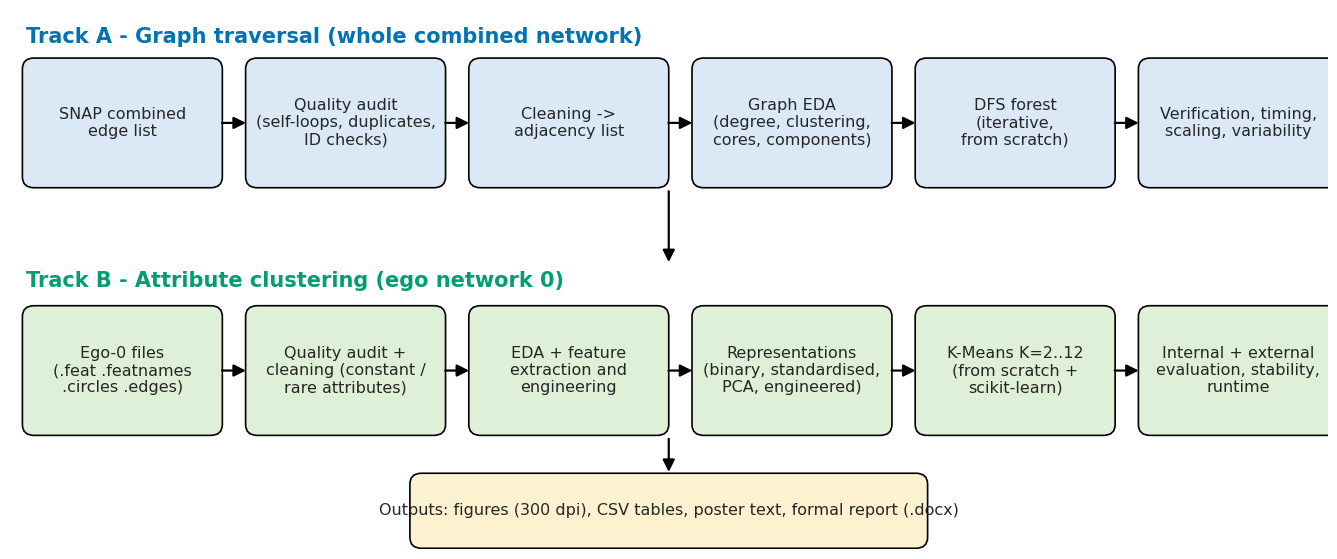

In [2]:
# ======================================================================================
# 4. METHODOLOGY OVERVIEW FIGURE (poster: "Methodology")
# ======================================================================================
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

def draw_pipeline():
    fig, ax = plt.subplots(figsize=(17, 7)); ax.axis("off"); ax.set_xlim(0, 17); ax.set_ylim(0, 7.4)
    def box(x, y, w, h, text, color):
        ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.04,rounding_size=0.15", fc=color, ec="black", lw=1.2))
        ax.text(x + w/2, y + h/2, text, ha="center", va="center", fontsize=11.5)
    def arrow(x1, y1, x2, y2):
        ax.add_patch(FancyArrowPatch((x1, y1), (x2, y2), arrowstyle="-|>", mutation_scale=18, lw=1.6, color="black"))
    A = ["SNAP combined\nedge list", "Quality audit\n(self-loops, duplicates,\nID checks)", "Cleaning ->\nadjacency list",
         "Graph EDA\n(degree, clustering,\ncores, components)", "DFS forest\n(iterative,\nfrom scratch)", "Verification, timing,\nscaling, variability"]
    B = ["Ego-0 files\n(.feat .featnames\n.circles .edges)", "Quality audit +\ncleaning (constant /\nrare attributes)", "EDA + feature\nextraction and\nengineering",
         "Representations\n(binary, standardised,\nPCA, engineered)", "K-Means K=2..12\n(from scratch +\nscikit-learn)", "Internal + external\nevaluation, stability,\nruntime"]
    w, gap, x0 = 2.5, 0.38, 0.2
    ax.text(x0, 6.95, "Track A - Graph traversal (whole combined network)", fontsize=15, fontweight="bold", color=PAL[0])
    ax.text(x0, 3.6, "Track B - Attribute clustering (ego network 0)", fontsize=15, fontweight="bold", color=PAL[2])
    for i, (a, b) in enumerate(zip(A, B)):
        x = x0 + i*(w + gap)
        box(x, 5.0, w, 1.7, a, "#dbe9f6"); box(x, 1.6, w, 1.7, b, "#dff0d8")
        if i < 5:
            arrow(x + w, 5.85, x + w + gap, 5.85); arrow(x + w, 2.45, x + w + gap, 2.45)
    box(5.2, 0.05, 6.6, 0.95, "Outputs: figures (300 dpi), CSV tables, poster text, formal report (.docx)", "#fdf2d0")
    arrow(8.5, 1.55, 8.5, 1.02); arrow(8.5, 4.95, 8.5, 3.9)
    return fig

fig = draw_pipeline()
save_fig(fig, "fig00_methodology_pipeline", "Methodology: two parallel tracks (graph traversal with DFS; attribute clustering with K-Means) from raw SNAP files to report and poster outputs.")


## 5. Data acquisition and file inventory

Two SNAP files are used: `facebook_combined.txt.gz` (all ego-network edges merged; used by DFS) and `facebook.tar.gz` (ten ego networks with `.edges`, `.feat`, `.featnames`, `.egofeat`, `.circles`; used by K-Means). The cell retries failed downloads and extracts the archive safely (no path traversal). If your runtime blocks `snap.stanford.edu`, download both files manually, upload them into the `facebook_project_data` folder shown below, and re-run — existing files are never re-downloaded.


In [3]:
SNAP_URLS = {
    "combined": "https://snap.stanford.edu/data/facebook_combined.txt.gz",
    "archive":  "https://snap.stanford.edu/data/facebook.tar.gz",
}
combined_path = DATA_DIR / "facebook_combined.txt.gz"
archive_path  = DATA_DIR / "facebook.tar.gz"
extract_dir   = DATA_DIR / "facebook"

def download_if_missing(url, dest, retries=3):
    if dest.exists() and dest.stat().st_size > 0:
        print(f"Already present: {dest.name} ({dest.stat().st_size/1e6:.2f} MB)"); return
    last = None
    for attempt in range(1, retries + 1):
        try:
            print(f"Downloading {dest.name} (attempt {attempt}) ...")
            urllib.request.urlretrieve(url, dest)
            if dest.stat().st_size > 0: return
        except Exception as e:
            last = e; time.sleep(2 * attempt)
    raise RuntimeError(f"Could not download {url} ({last}). Download it manually and place it in {DATA_DIR}.")

def safe_extract(tar_path, dest):
    dest = dest.resolve()
    with tarfile.open(tar_path, "r:gz") as tar:
        for m in tar.getmembers():
            target = (dest / m.name).resolve()
            if not str(target).startswith(str(dest)) or not (m.isfile() or m.isdir()):
                continue                                   # skip unsafe / special members
            try:
                tar.extract(m, dest, filter="data")
            except TypeError:                              # Python < 3.12 has no `filter`
                tar.extract(m, dest)

with timed("Download + extract SNAP files", "Network + disk") as t_dl:
    download_if_missing(SNAP_URLS["combined"], combined_path)
    download_if_missing(SNAP_URLS["archive"], archive_path)
    if not list(DATA_DIR.rglob("0.feat")):
        print("Extracting ego-network archive ...")
        safe_extract(archive_path, DATA_DIR)

feat_hits = list(DATA_DIR.rglob("0.feat"))
if not feat_hits:
    raise FileNotFoundError("0.feat not found after extraction.")
EGO_DIR = feat_hits[0].parent
print("Ego-network directory:", EGO_DIR)

# ---- Inventory of all ego networks in the archive ----------------------------------------------------
def count_lines(p):
    with open(p, "r", encoding="utf-8") as f:
        return sum(1 for ln in f if ln.strip())
inv = []
for fn in sorted(EGO_DIR.glob("*.featnames"), key=lambda p: int(p.stem)):
    e = fn.stem
    inv.append({"ego_id": int(e),
                "nodes_in_feat": count_lines(EGO_DIR / f"{e}.feat") if (EGO_DIR / f"{e}.feat").exists() else np.nan,
                "attributes": count_lines(fn),
                "edges_in_ego_file": count_lines(EGO_DIR / f"{e}.edges") if (EGO_DIR / f"{e}.edges").exists() else np.nan,
                "circles": count_lines(EGO_DIR / f"{e}.circles") if (EGO_DIR / f"{e}.circles").exists() else 0})
inventory_df = pd.DataFrame(inv)
display(inventory_df)
save_table(inventory_df, "ego_network_inventory")
R["data"] = {"combined_file_mb": combined_path.stat().st_size/1e6, "archive_file_mb": archive_path.stat().st_size/1e6,
             "n_ego_networks": len(inventory_df), "download_seconds": t_dl["seconds"]}


Extracting ego-network archive ...
Ego-network directory: /content/facebook_project_data/facebook


,ego_id,nodes_in_feat,attributes,edges_in_ego_file,circles
0,0,347,224,5038,24
1,107,1045,576,53498,9
2,348,227,161,6384,14
3,414,159,105,3386,7
4,686,170,63,3312,14
5,698,66,48,540,13
6,1684,792,319,28048,17
7,1912,755,480,60050,46
8,3437,547,262,9626,32
9,3980,59,42,292,17


## 6. Part A — Combined graph: quality audit, cleaning and EDA

### 6.1 Load and audit the raw edge list
Every raw record is checked before any cleaning: malformed lines, self-loops, duplicate / reversed duplicate edges, node-ID range and continuity. The graph is **undirected**, so `(u, v)` and `(v, u)` are the same edge.


In [4]:
SNAP_REFERENCE = {"nodes": 4039, "edges": 88234, "average_clustering": 0.6055, "triangles": 1612010,
                  "transitivity": 0.2647, "diameter": 8}      # published on the SNAP dataset page (for sanity check only)

with timed("Load + audit combined edge list", "Parse gz file into raw edge records") as t_load:
    raw_edges, malformed, comment_lines = [], 0, 0
    with gzip.open(combined_path, "rt", encoding="utf-8") as f:
        for line in f:
            s = line.strip()
            if not s: continue
            if s.startswith("#"): comment_lines += 1; continue
            p = s.split()
            if len(p) != 2: malformed += 1; continue
            try: raw_edges.append((int(p[0]), int(p[1])))
            except ValueError: malformed += 1

raw_records  = len(raw_edges)
self_loops   = sum(1 for u, v in raw_edges if u == v)
canon        = {(min(u, v), max(u, v)) for u, v in raw_edges if u != v}
dup_records  = raw_records - self_loops - len(canon)          # repeated or reversed duplicates
all_ids      = sorted({x for e in raw_edges for x in e})
id_min, id_max = all_ids[0], all_ids[-1]
missing_ids  = (id_max - id_min + 1) - len(all_ids)

audit_df = pd.DataFrame([
    ("Raw edge records", raw_records, "Lines parsed as `u v`"),
    ("Malformed / non-integer lines", malformed, "Dropped"),
    ("Self-loops", self_loops, "Removed (a user is not their own friend)"),
    ("Duplicate or reversed-duplicate records", dup_records, "Collapsed to one undirected edge"),
    ("Unique undirected edges after cleaning", len(canon), "Used for all graph analysis"),
    ("Distinct node IDs", len(all_ids), "Nodes appear only through edges, so isolates cannot exist in an edge list"),
    ("Node-ID range", f"{id_min} .. {id_max}", f"{missing_ids} IDs missing inside the range"),
], columns=["check", "value", "decision"])
display(audit_df)
save_table(audit_df, "graph_quality_audit")
R["graph_audit"] = {"raw_records": raw_records, "malformed": malformed, "self_loops": self_loops,
                    "duplicates": dup_records, "unique_edges": len(canon), "nodes": len(all_ids),
                    "id_min": id_min, "id_max": id_max, "missing_ids": missing_ids, "load_seconds": t_load["seconds"]}


,check,value,decision
0,Raw edge records,88234,Lines parsed as `u v`
1,Malformed / non-integer lines,0,Dropped
2,Self-loops,0,Removed (a user is not their own friend)
3,Duplicate or reversed-duplicate records,0,Collapsed to one undirected edge
4,Unique undirected edges after cleaning,88234,Used for all graph analysis
5,Distinct node IDs,4039,"Nodes appear only through edges, so isolates c..."
6,Node-ID range,0 .. 4038,0 IDs missing inside the range


### 6.2 Cleaning and 6.3 Graph EDA
Self-loops and duplicate/reversed edges are removed, adjacency lists are built (sorted, so DFS is deterministic) and symmetry is asserted. EDA then profiles degree, clustering, k-cores, components and a sampled diameter, and **cross-checks the results against the statistics published on the SNAP page** to detect a wrong or corrupted file.


Clean graph: |V|=4,039  |E|=88,234  (cleaning took 0.284 s)


,statistic,this_run,snap_published,agrees
0,nodes,4.039000e+03,4.039000e+03,True
1,edges,8.823400e+04,8.823400e+04,True
2,average_clustering,6.055467e-01,6.055000e-01,True
3,triangles,1.612010e+06,1.612010e+06,True
4,transitivity,5.191743e-01,2.647000e-01,False
5,diameter,8.000000e+00,8.000000e+00,lower bound <= 8: True


NOTE: some statistics differ from the SNAP page. Check that the correct, unmodified file was loaded.


,metric,value
0,nodes,4.039000e+03
1,edges,8.823400e+04
2,density,1.081996e-02
3,avg_degree,4.369101e+01
4,median_degree,2.500000e+01
5,max_degree,1.045000e+03
6,min_degree,1.000000e+00
7,std_degree,5.241412e+01
8,avg_clustering,6.055467e-01
9,transitivity,5.191743e-01


,node,degree,clustering,core
107,107,1045,0.049038,70
1684,1684,792,0.044775,43
1912,1912,755,0.105486,115
3437,3437,547,0.032230,22
0,0,347,0.041962,21
2543,2543,294,0.359917,115
2347,2347,291,0.399645,115
1888,1888,254,0.399676,70
1800,1800,245,0.402041,70
1663,1663,235,0.416512,70


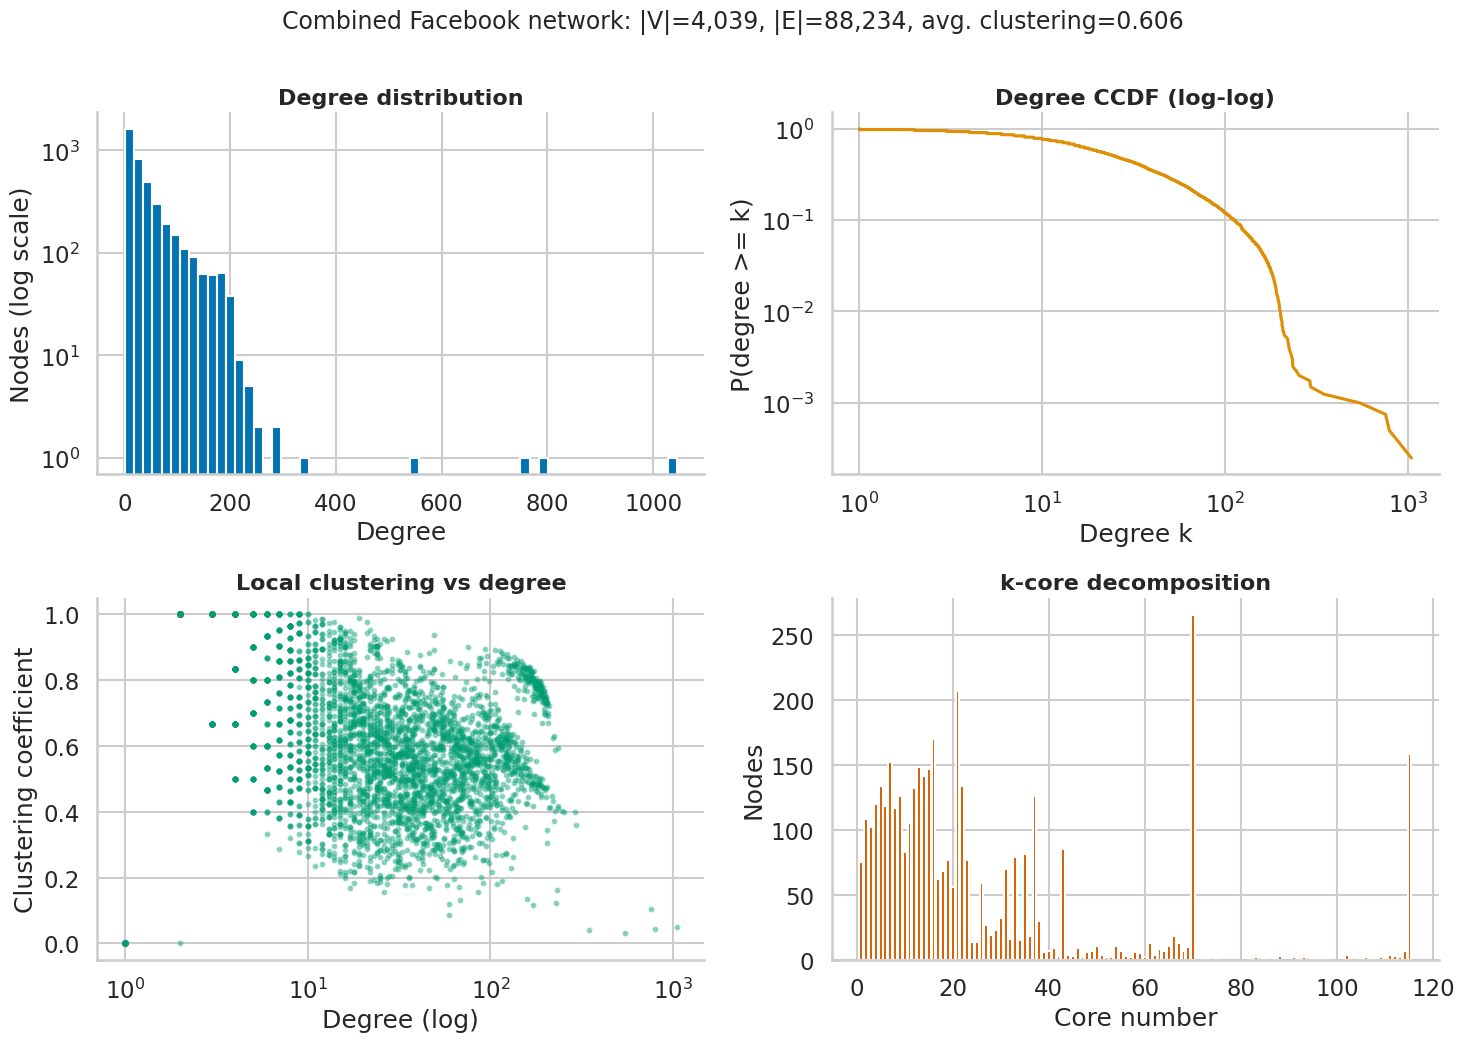

In [5]:
# ---- 6.2 Cleaning: build the clean undirected graph and the adjacency list used by our own DFS ----------
with timed("Clean graph + build adjacency list", "Drop self-loops/duplicates, build sorted adjacency lists") as t_clean:
    G = nx.Graph(); G.add_edges_from(sorted(canon))
    NODES = sorted(G.nodes())
    ADJ = {u: sorted(G.adj[u]) for u in NODES}                 # adjacency list (sorted => deterministic DFS)
    EDGES = sorted(canon)

assert all(u in ADJ[v] for u, v in EDGES), "adjacency list is not symmetric"
assert sum(len(v) for v in ADJ.values()) == 2 * len(EDGES), "adjacency size mismatch"
print(f"Clean graph: |V|={len(NODES):,}  |E|={len(EDGES):,}  (cleaning took {t_clean['seconds']:.3f} s)")

# ---- 6.3 Graph EDA ---------------------------------------------------------------------------------------------
with timed("Graph EDA metrics", "Clustering, k-core, components, sampled diameter") as t_eda:
    deg = np.array([len(ADJ[u]) for u in NODES])
    clustering = nx.clustering(G)
    clus_arr = np.array([clustering[u] for u in NODES])
    core = nx.core_number(G); core_arr = np.array([core[u] for u in NODES])
    comps = sorted((len(c) for c in nx.connected_components(G)), reverse=True)
    triangles = sum(nx.triangles(G).values()) // 3
    rng = np.random.default_rng(SEED)
    srcs = rng.choice(NODES, size=min(CFG["DIAMETER_SAMPLE"], len(NODES)), replace=False)
    ecc, path_means = [], []
    for s in srcs:
        d = nx.single_source_shortest_path_length(G, int(s))
        ecc.append(max(d.values())); path_means.append(np.mean(list(d.values())))

gstats = {
    "nodes": len(NODES), "edges": len(EDGES), "density": nx.density(G), "avg_degree": float(deg.mean()),
    "median_degree": float(np.median(deg)), "max_degree": int(deg.max()), "min_degree": int(deg.min()),
    "std_degree": float(deg.std()), "avg_clustering": float(clus_arr.mean()), "transitivity": nx.transitivity(G),
    "triangles": int(triangles), "max_core": int(core_arr.max()), "components": len(comps),
    "largest_component": comps[0], "diameter_lower_bound": int(max(ecc)), "avg_path_length_est": float(np.mean(path_means)),
    "assortativity": float(nx.degree_assortativity_coefficient(G)), "clean_seconds": t_clean["seconds"],
}
R["graph"] = gstats

ref_rows = []
for key, ours in [("nodes", gstats["nodes"]), ("edges", gstats["edges"]), ("average_clustering", gstats["avg_clustering"]),
                  ("triangles", gstats["triangles"]), ("transitivity", gstats["transitivity"]), ("diameter", gstats["diameter_lower_bound"])]:
    ref = SNAP_REFERENCE[key]
    ref_rows.append({"statistic": key, "this_run": ours, "snap_published": ref,
                     "agrees": bool(np.isclose(ours, ref, rtol=5e-3)) if key != "diameter" else f"lower bound <= {ref}: {ours <= ref}"})
snap_check_df = pd.DataFrame(ref_rows)
display(snap_check_df); save_table(snap_check_df, "graph_vs_snap_reference")
if not all(r["agrees"] is True for r in ref_rows[:5]):
    print("NOTE: some statistics differ from the SNAP page. Check that the correct, unmodified file was loaded.")

graph_profile_df = pd.DataFrame([{"metric": k, "value": v} for k, v in gstats.items()])
display(graph_profile_df); save_table(graph_profile_df, "graph_summary")

top_hubs = pd.DataFrame({"node": NODES, "degree": deg, "clustering": clus_arr, "core": core_arr}).sort_values("degree", ascending=False).head(10)
display(top_hubs); save_table(top_hubs, "graph_top_hubs")

fig, ax = plt.subplots(2, 2, figsize=(15, 10.5))
ax[0, 0].hist(deg, bins=60, color=PAL[0]); ax[0, 0].set_yscale("log"); ax[0, 0].set(title="Degree distribution", xlabel="Degree", ylabel="Nodes (log scale)")
sd = np.sort(deg); ccdf = 1 - np.arange(len(sd)) / len(sd)
ax[0, 1].loglog(sd, ccdf, color=PAL[1]); ax[0, 1].set(title="Degree CCDF (log-log)", xlabel="Degree k", ylabel="P(degree >= k)")
ax[1, 0].scatter(deg, clus_arr, s=8, alpha=0.35, color=PAL[2]); ax[1, 0].set_xscale("log")
ax[1, 0].set(title="Local clustering vs degree", xlabel="Degree (log)", ylabel="Clustering coefficient")
vals, cnt = np.unique(core_arr, return_counts=True); ax[1, 1].bar(vals, cnt, color=PAL[3]); ax[1, 1].set(title="k-core decomposition", xlabel="Core number", ylabel="Nodes")
fig.suptitle(f"Combined Facebook network: |V|={gstats['nodes']:,}, |E|={gstats['edges']:,}, avg. clustering={gstats['avg_clustering']:.3f}", fontsize=17, y=1.0)
fig.tight_layout()
save_fig(fig, "fig01_graph_eda", "Exploratory analysis of the combined network: heavy-tailed degree distribution, high local clustering and nested k-core structure.")


## 7. Algorithm 1 — Depth-First Search (DFS)

### 7.1 Implementation

**Implementation.** A from-scratch *iterative* DFS (explicit stack of neighbour iterators, so deep graphs cannot hit Python's recursion limit) over an adjacency list. It records, for every node, the **parent**, **depth**, **discovery time** and **finishing time**. It is run once per connected component (a DFS *forest*), so the whole graph is covered. Complexity is *O(V + E)* time and *O(V)* extra space.

**Why discovery/finishing times?** They allow an *independent* correctness test (§7.2): in an undirected graph, every edge must join an ancestor and a descendant, i.e. the two nodes' [discovery, finish] intervals must be nested.


In [6]:
def dfs_forest(adj, roots=None):
    """Iterative DFS over an adjacency list. roots=None -> full forest over all nodes (sorted order).
    Returns order, parent, depth, discovery and finishing times and the number of DFS roots."""
    disc, fin, parent, depth, order = {}, {}, {}, {}, []
    t, n_roots = 0, 0
    for r in (adj.keys() if roots is None else roots):
        if r in disc: continue
        n_roots += 1
        parent[r], depth[r] = None, 0
        t += 1; disc[r] = t; order.append(r)
        stack = [(r, iter(adj[r]))]
        while stack:
            u, it = stack[-1]
            for w in it:
                if w not in disc:
                    parent[w], depth[w] = u, depth[u] + 1
                    t += 1; disc[w] = t; order.append(w)
                    stack.append((w, iter(adj[w])))
                    break
            else:                                   # all neighbours explored -> backtrack
                t += 1; fin[u] = t; stack.pop()
    return {"order": order, "parent": parent, "depth": depth, "disc": disc, "fin": fin, "n_roots": n_roots}

# ---- Unit test on a tiny graph with a known DFS result -----------------------------------------------
toy = {1: [2, 3], 2: [1, 4], 3: [1, 4], 4: [2, 3, 5], 5: [4]}
toy_res = dfs_forest(toy)
assert toy_res["order"] == [1, 2, 4, 3, 5], toy_res["order"]
assert toy_res["parent"] == {1: None, 2: 1, 4: 2, 3: 4, 5: 4}
print("Unit test passed. Toy DFS order:", toy_res["order"])

# ---- Main run: DFS forest over the whole cleaned graph -------------------------------------------------
with timed("DFS forest (all components)", "From-scratch iterative DFS incl. parent/depth/discovery/finish") as t_dfs:
    DFS = dfs_forest(ADJ)
print(f"DFS finished in {t_dfs['seconds']:.4f} s | visited {len(DFS['order']):,} of {len(NODES):,} nodes | roots used: {DFS['n_roots']}")
print("First 20 nodes in DFS order:", DFS["order"][:20])


Unit test passed. Toy DFS order: [1, 2, 4, 3, 5]
DFS finished in 0.0430 s | visited 4,039 of 4,039 nodes | roots used: 1
First 20 nodes in DFS order: [0, 1, 48, 30, 9, 3, 25, 21, 13, 26, 40, 29, 16, 82, 56, 55, 67, 10, 142, 31]


### 7.2 Correctness verification ("DFS accuracy")
DFS has no prediction target, so classification accuracy is undefined. Instead, **verification accuracy** = share of independent correctness checks passed, plus the **percentage of graph edges that satisfy the DFS ancestor–descendant property**. All checks use information that the algorithm did *not* use to build the tree (NetworkX components, the edge set, and nested discovery/finish intervals).

### 7.3 Timing, scaling and variability
Runtime is measured with `time.perf_counter` over repeated runs (mean ± std), compared with NetworkX's DFS as a reference implementation, and then checked for *O(V + E)* scaling on random induced sub-networks.


In [7]:
order, parent, depth, disc, fin = DFS["order"], DFS["parent"], DFS["depth"], DFS["disc"], DFS["fin"]
edge_set = set(EDGES)
idx = {n: i for i, n in enumerate(NODES)}
disc_a = np.array([disc[n] for n in NODES]); fin_a = np.array([fin[n] for n in NODES])
U = np.array([idx[u] for u, v in EDGES]); W = np.array([idx[v] for u, v in EDGES])
nested = ((disc_a[U] < disc_a[W]) & (fin_a[W] < fin_a[U])) | ((disc_a[W] < disc_a[U]) & (fin_a[U] < fin_a[W]))
edge_property_pct = 100 * nested.mean()

tree_edges = [(min(n, p), max(n, p)) for n, p in parent.items() if p is not None]
nx_components = nx.number_connected_components(G)
nx_reach = set(nx.dfs_preorder_nodes(G, source=order[0]))
comp_of_root = set(nx.node_connected_component(G, order[0]))

checks = [
    ("Every node visited exactly once (no duplicates)", len(order) == len(set(order)) == len(NODES)),
    ("Visited set equals the node set", set(order) == set(NODES)),
    ("Number of DFS roots equals NetworkX connected components", DFS["n_roots"] == nx_components),
    ("Every tree edge exists in the graph", all(e in edge_set for e in tree_edges)),
    ("Tree edge count = V - number of components", len(tree_edges) == len(NODES) - DFS["n_roots"]),
    ("Set reached from the first root equals NetworkX DFS reachable set", nx_reach == comp_of_root),
    ("Every edge joins an ancestor and a descendant (nested intervals)", bool(nested.all())),
    ("Discovery times are unique and finish > discovery for all nodes", len(set(disc.values())) == len(NODES) and bool((fin_a > disc_a).all())),
]
checks_df = pd.DataFrame([{"check": c, "passed": bool(ok)} for c, ok in checks])
display(checks_df); save_table(checks_df, "dfs_verification_checks")

n_tree = len(tree_edges); n_back = len(EDGES) - n_tree
dfs_acc = {"checks_passed": int(checks_df.passed.sum()), "checks_total": len(checks_df),
           "verification_accuracy_pct": 100 * checks_df.passed.mean(), "edge_property_pct": edge_property_pct,
           "coverage_pct": 100 * len(set(order)) / len(NODES), "roots": DFS["n_roots"], "tree_edges": n_tree,
           "back_edges": n_back, "tree_height": int(max(depth.values())), "mean_depth": float(np.mean(list(depth.values()))),
           "has_cycles": n_back > 0}
print(f"Verification accuracy: {dfs_acc['verification_accuracy_pct']:.1f}% ({dfs_acc['checks_passed']}/{dfs_acc['checks_total']} checks) | "
      f"edges satisfying DFS property: {edge_property_pct:.2f}% | tree height {dfs_acc['tree_height']} | back edges {n_back:,}")

# ---- Timing: repeated runs, own DFS vs NetworkX reference ----------------------------------------------------
import tracemalloc, gc
def time_repeated(fn, repeats):
    """Wall-clock timings with the garbage collector paused (as in timeit) to avoid GC spikes."""
    out = []; gc.collect(); gc.disable()
    try:
        for _ in range(repeats):
            t0 = time.perf_counter(); fn(); out.append(time.perf_counter() - t0)
    finally:
        gc.enable()
    return np.array(out)

def nx_dfs_all():
    seen = set()
    for n in G:
        if n not in seen:
            seen.update(nx.dfs_preorder_nodes(G, source=n))
    return seen

with timed("DFS timing benchmark", f"{CFG['DFS_REPEATS']} repeats of own DFS and NetworkX DFS") as t_bench:
    own_t = time_repeated(lambda: dfs_forest(ADJ), CFG["DFS_REPEATS"])
    nx_t = time_repeated(nx_dfs_all, CFG["DFS_REPEATS"])
tracemalloc.start(); dfs_forest(ADJ); peak_mb = tracemalloc.get_traced_memory()[1] / 1e6; tracemalloc.stop()

def ci95(a): return float(stats.t.ppf(0.975, len(a) - 1) * a.std(ddof=1) / np.sqrt(len(a)))
dfs_acc.update({"own_mean_s": float(own_t.mean()), "own_std_s": float(own_t.std(ddof=1)), "own_min_s": float(own_t.min()),
                "own_median_s": float(np.median(own_t)), "own_ci95_s": ci95(own_t), "nx_mean_s": float(nx_t.mean()),
                "nx_std_s": float(nx_t.std(ddof=1)), "peak_memory_mb": float(peak_mb), "repeats": CFG["DFS_REPEATS"]})
timing_df = pd.DataFrame([
    {"implementation": "From-scratch iterative DFS (with parent/depth/disc/fin)", "mean_s": own_t.mean(), "std_s": own_t.std(ddof=1), "min_s": own_t.min(), "median_s": np.median(own_t)},
    {"implementation": "NetworkX dfs_preorder_nodes (order only, reference)", "mean_s": nx_t.mean(), "std_s": nx_t.std(ddof=1), "min_s": nx_t.min(), "median_s": np.median(nx_t)}])
display(timing_df); save_table(timing_df, "dfs_timing")
print(f"Peak extra memory of one DFS run: {peak_mb:.2f} MB. NetworkX does less bookkeeping (no times/depth), so compare orders of magnitude only.")
R["dfs"] = dfs_acc


,check,passed
0,Every node visited exactly once (no duplicates),True
1,Visited set equals the node set,True
2,Number of DFS roots equals NetworkX connected ...,True
3,Every tree edge exists in the graph,True
4,Tree edge count = V - number of components,True
5,Set reached from the first root equals Network...,True
6,Every edge joins an ancestor and a descendant ...,True
7,Discovery times are unique and finish > discov...,True


Verification accuracy: 100.0% (8/8 checks) | edges satisfying DFS property: 100.00% | tree height 1858 | back edges 84,196


,implementation,mean_s,std_s,min_s,median_s
0,From-scratch iterative DFS (with parent/depth/...,0.036132,0.007935,0.032208,0.033778
1,"NetworkX dfs_preorder_nodes (order only, refer...",0.141501,0.064921,0.060802,0.154772


Peak extra memory of one DFS run: 1.07 MB. NetworkX does less bookkeeping (no times/depth), so compare orders of magnitude only.


Linear fit time ~ a*(V+E)+b: R^2 = 0.8985, slope = 0.303 microseconds per (V+E) unit


,visited,tree_height,mean_depth
mean,4039.0,2196.2,1270.041471
min,4039.0,1717.0,1058.906908
max,4039.0,2650.0,1474.473880


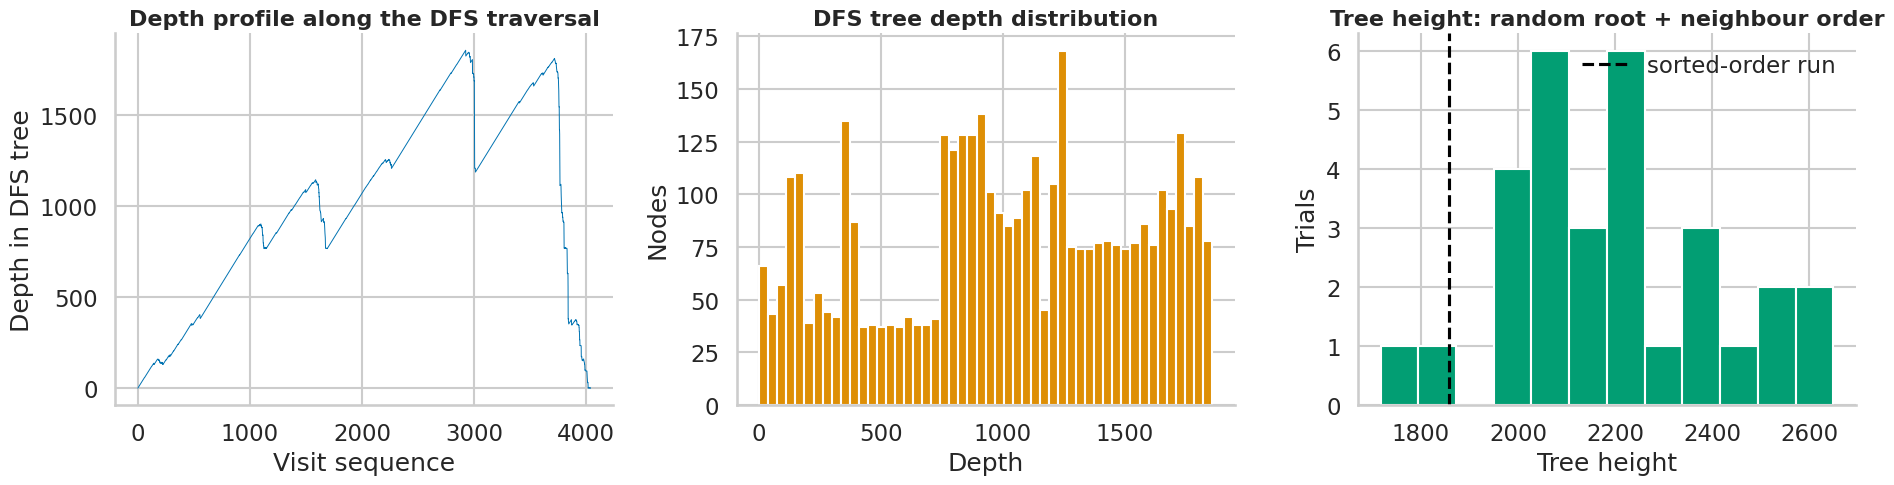

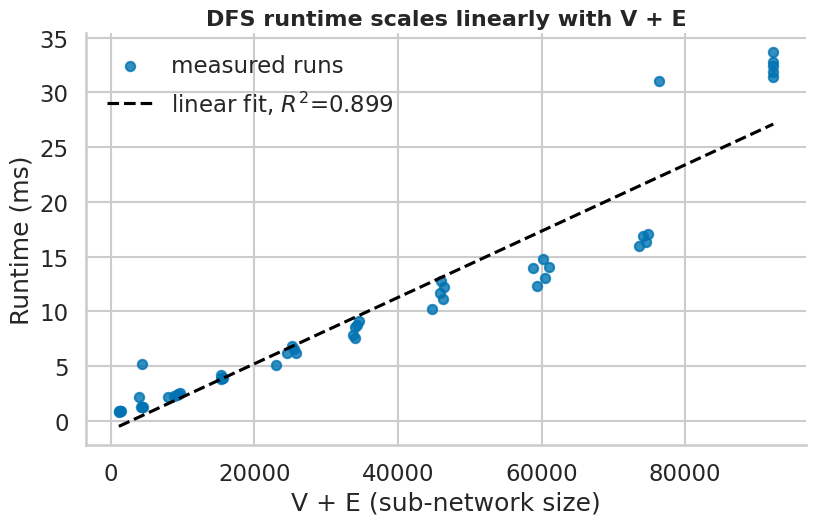

In [8]:
# ---- Empirical complexity: DFS time vs (V+E) on random induced sub-networks ---------------------------------
rng = np.random.default_rng(SEED)
scale_rows = []
with timed("DFS scaling experiment", "Random induced sub-graphs, 10 sizes x repeats") as t_scale:
    for frac in CFG["SCALING_FRACTIONS"]:
        for rep in range(CFG["SCALING_REPEATS"]):
            keep = set(rng.choice(NODES, size=max(2, int(frac * len(NODES))), replace=False).tolist())
            sub = {u: [w for w in ADJ[u] if w in keep] for u in keep}
            e_sub = sum(len(v) for v in sub.values()) // 2
            gc.collect(); gc.disable()
            try:
                dt_ = float('inf')
                for _ in range(3):                       # best of 3 removes scheduler noise
                    t0 = time.perf_counter(); res = dfs_forest(sub); dt_ = min(dt_, time.perf_counter() - t0)
            finally:
                gc.enable()
            scale_rows.append({"fraction": frac, "V": len(sub), "E": e_sub, "V_plus_E": len(sub) + e_sub,
                               "components": res["n_roots"], "seconds": dt_})
scale_df = pd.DataFrame(scale_rows); save_table(scale_df, "dfs_scaling")
lr = stats.linregress(scale_df.V_plus_E, scale_df.seconds)
R["dfs"].update({"scaling_slope_us_per_unit": lr.slope * 1e6, "scaling_r2": lr.rvalue ** 2, "scaling_intercept_s": lr.intercept})
print(f"Linear fit time ~ a*(V+E)+b: R^2 = {lr.rvalue**2:.4f}, slope = {lr.slope*1e6:.3f} microseconds per (V+E) unit")

# ---- Variability: DFS tree shape depends on root and neighbour order ----------------------------------------
var_rows = []
with timed("DFS variability trials", f"{CFG['DFS_VARIABILITY_TRIALS']} random root / neighbour-order trials") as t_var:
    for trial in range(CFG["DFS_VARIABILITY_TRIALS"]):
        r = int(rng.choice(NODES))
        shuffled = {u: rng.permutation(ADJ[u]).tolist() for u in NODES}
        res = dfs_forest(shuffled, roots=[r])
        var_rows.append({"trial": trial, "root": r, "visited": len(res["order"]), "tree_height": max(res["depth"].values()),
                         "mean_depth": float(np.mean(list(res["depth"].values())))})
var_df = pd.DataFrame(var_rows); save_table(var_df, "dfs_variability")
R["dfs"].update({"var_height_min": int(var_df.tree_height.min()), "var_height_max": int(var_df.tree_height.max()),
                 "var_height_mean": float(var_df.tree_height.mean()), "var_visited_min": int(var_df.visited.min())})
display(var_df.describe().loc[["mean", "min", "max"], ["visited", "tree_height", "mean_depth"]])

# ---- Figures ------------------------------------------------------------------------------------------------------
fig, ax = plt.subplots(1, 3, figsize=(19, 5.2))
ax[0].plot(range(1, len(order) + 1), [depth[n] for n in order], lw=0.7, color=PAL[0])
ax[0].set(title="Depth profile along the DFS traversal", xlabel="Visit sequence", ylabel="Depth in DFS tree")
ax[1].hist(list(depth.values()), bins=50, color=PAL[1]); ax[1].set(title="DFS tree depth distribution", xlabel="Depth", ylabel="Nodes")
ax[2].hist(var_df.tree_height, bins=12, color=PAL[2]); ax[2].axvline(dfs_acc["tree_height"], color="black", ls="--", label="sorted-order run")
ax[2].set(title="Tree height: random root + neighbour order", xlabel="Tree height", ylabel="Trials"); ax[2].legend()
fig.tight_layout(); save_fig(fig, "fig02_dfs_analysis", "DFS behaviour on the combined network: long chains along the traversal (left), depth distribution (middle) and sensitivity of tree height to root and neighbour order (right).")

fig, ax = plt.subplots(figsize=(8.5, 5.6))
ax.scatter(scale_df.V_plus_E, scale_df.seconds * 1e3, s=45, color=PAL[0], alpha=0.8, label="measured runs")
xs = np.linspace(scale_df.V_plus_E.min(), scale_df.V_plus_E.max(), 50)
ax.plot(xs, (lr.slope * xs + lr.intercept) * 1e3, color="black", ls="--", label=f"linear fit, $R^2$={lr.rvalue**2:.3f}")
ax.set(title="DFS runtime scales linearly with V + E", xlabel="V + E (sub-network size)", ylabel="Runtime (ms)"); ax.legend()
fig.tight_layout(); save_fig(fig, "fig03_dfs_scaling", "Empirical O(V+E) behaviour of the from-scratch DFS on random induced sub-networks.")


### 7.4 Illustrative DFS tree
Drawing 4,039 nodes is unreadable, so the DFS tree is illustrated on ego network 0 (about 350 nodes).


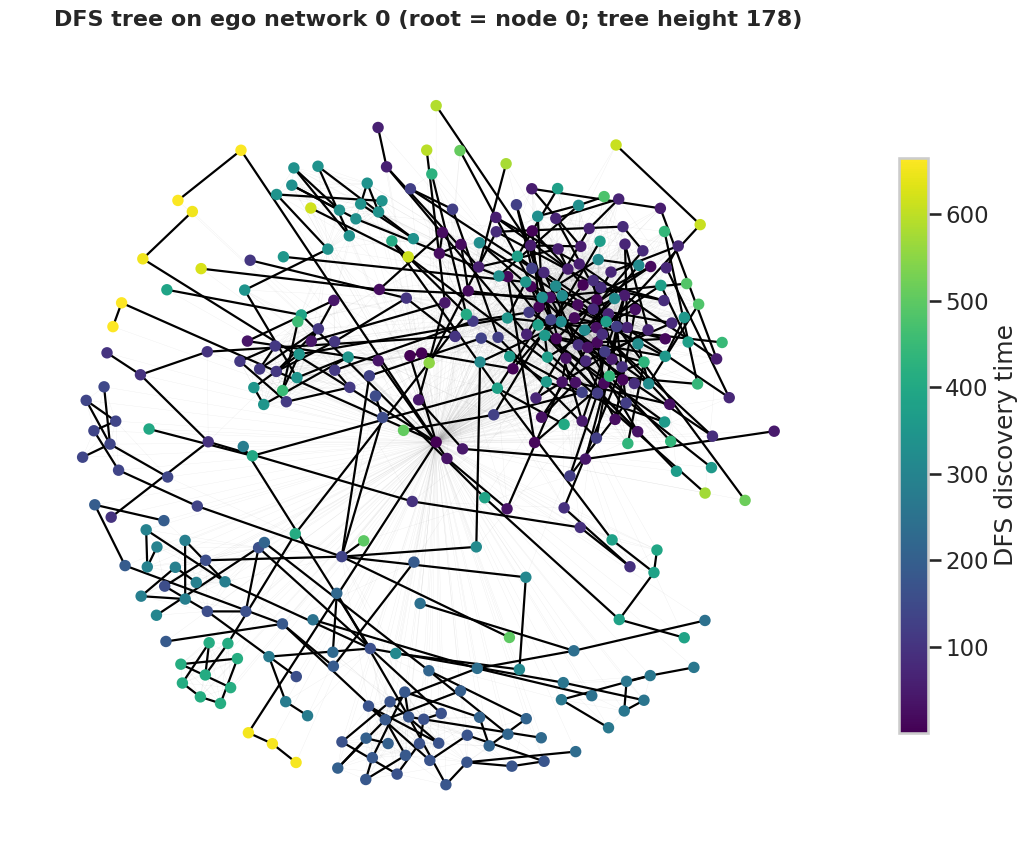

In [9]:
# ---- Illustrative DFS tree on ego network 0 (readable size) -------------------------------------------------------
ego_edge_file = EGO_DIR / f"{CFG['EGO_ID']}.edges"
ego_nodes_demo = set()
with open(ego_edge_file) as f:
    for ln in f:
        p = ln.split()
        if len(p) == 2: ego_nodes_demo.update((int(p[0]), int(p[1])))
ego_nodes_demo.add(CFG["EGO_ID"])
sub = G.subgraph([n for n in ego_nodes_demo if n in G]).copy()
sub_adj = {u: sorted(sub.adj[u]) for u in sub.nodes()}
root_demo = CFG["EGO_ID"] if CFG["EGO_ID"] in sub else max(sub.degree, key=lambda x: x[1])[0]
res_demo = dfs_forest(sub_adj, roots=[root_demo])
pos = nx.spring_layout(sub, seed=SEED, k=0.35, iterations=80)
tree_e = {(min(n, p), max(n, p)) for n, p in res_demo["parent"].items() if p is not None}
back_e = [e for e in sub.edges() if (min(e), max(e)) not in tree_e]
fig, ax = plt.subplots(figsize=(11, 9))
nx.draw_networkx_edges(sub, pos, edgelist=back_e, width=0.25, alpha=0.15, edge_color="gray", ax=ax)
nx.draw_networkx_edges(sub, pos, edgelist=list(tree_e), width=1.6, edge_color="black", ax=ax)
nc = nx.draw_networkx_nodes(sub, pos, node_size=45, node_color=[res_demo["disc"].get(n, 0) for n in sub.nodes()], cmap="viridis", ax=ax)
plt.colorbar(nc, ax=ax, shrink=0.7, label="DFS discovery time")
ax.set_title(f"DFS tree on ego network {CFG['EGO_ID']} (root = node {root_demo}; tree height {max(res_demo['depth'].values())})"); ax.axis("off")
fig.tight_layout(); save_fig(fig, "fig04_dfs_tree_ego0", "DFS on ego network 0: black edges form the DFS tree, grey edges are back edges; colour shows discovery order.")
R["dfs"].update({"demo_nodes": sub.number_of_nodes(), "demo_edges": sub.number_of_edges(), "demo_height": int(max(res_demo["depth"].values()))})


## 8. Part B — Ego network 0: attribute data

### 8.1 Load features, attribute names, edges and circles
`0.feat` = node ID followed by binary profile attributes; `0.featnames` gives anonymised attribute names such as `education;classes;id;anonymized feature 53` (the part before `;anonymized feature` is the attribute **category**); `0.circles` lists manually defined friend lists (circles may overlap); `0.edges` gives friendships inside the ego network. The ego user's own row (`0.egofeat`) is not part of `0.feat` and is therefore not clustered.


In [10]:
EGO = CFG["EGO_ID"]
def read_int_rows(path):
    rows, bad = [], 0
    with open(path, "r", encoding="utf-8") as f:
        for line in f:
            p = line.split()
            if not p: continue
            try: rows.append([int(x) for x in p])
            except ValueError: bad += 1
    return rows, bad

with timed("Load ego-0 feature file", "Parse 0.feat, 0.featnames, 0.edges, 0.circles") as t_feat:
    rows, bad_rows = read_int_rows(EGO_DIR / f"{EGO}.feat")
    if len({len(r) for r in rows}) != 1: raise ValueError("Inconsistent row lengths in feature file.")
    node_ids = np.array([r[0] for r in rows], dtype=int)
    X_raw = np.array([r[1:] for r in rows], dtype=float)

    names, cats = [], []
    with open(EGO_DIR / f"{EGO}.featnames", encoding="utf-8") as f:
        for line in f:
            m = re.match(r"^\s*(\d+)\s+(.*?)\s*$", line)
            if not m: continue
            full = m.group(2)
            cats.append(re.sub(r";?anonymized feature \d+\s*$", "", full).strip(";") or "unknown")
            names.append(full)
    if len(names) != X_raw.shape[1]:
        warnings.warn("featnames length differs from feature width; using generic names")
        names = [f"feature_{i}" for i in range(X_raw.shape[1])]; cats = ["unknown"] * X_raw.shape[1]
    cats = np.array(cats); feat_ids = [f"{c}#{i}" for i, c in enumerate(cats)]

    ego_G = nx.read_edgelist(EGO_DIR / f"{EGO}.edges", nodetype=int)

    circles, node_circles = {}, defaultdict(list)
    if (EGO_DIR / f"{EGO}.circles").exists():
        with open(EGO_DIR / f"{EGO}.circles", encoding="utf-8") as f:
            for line in f:
                p = line.split()
                if len(p) < 2: continue
                members = []
                for tok in p[1:]:
                    try: members.append(int(tok))
                    except ValueError: pass
                circles[p[0]] = members
                for m_ in members: node_circles[m_].append(p[0])

print(f"Feature matrix: {X_raw.shape[0]} nodes x {X_raw.shape[1]} attributes | {len(set(cats))} categories | "
      f"{len(circles)} circles | ego edges: {ego_G.number_of_edges()} | unreadable rows: {bad_rows}")


Feature matrix: 347 nodes x 224 attributes | 21 categories | 24 circles | ego edges: 2519 | unreadable rows: 0


,check,value
0,Nodes (rows),347.0000
1,Attributes (columns),224.0000
2,Missing / NaN values,0.0000
3,Non-binary values,0.0000
4,Duplicate node IDs,0.0000
5,Nodes sharing an identical attribute vector wi...,60.0000
6,Nodes with zero active attributes,0.0000
7,All-zero attributes (constant),0.0000
8,All-one attributes (constant),0.0000
9,Rare attributes (< 5 nodes),109.0000


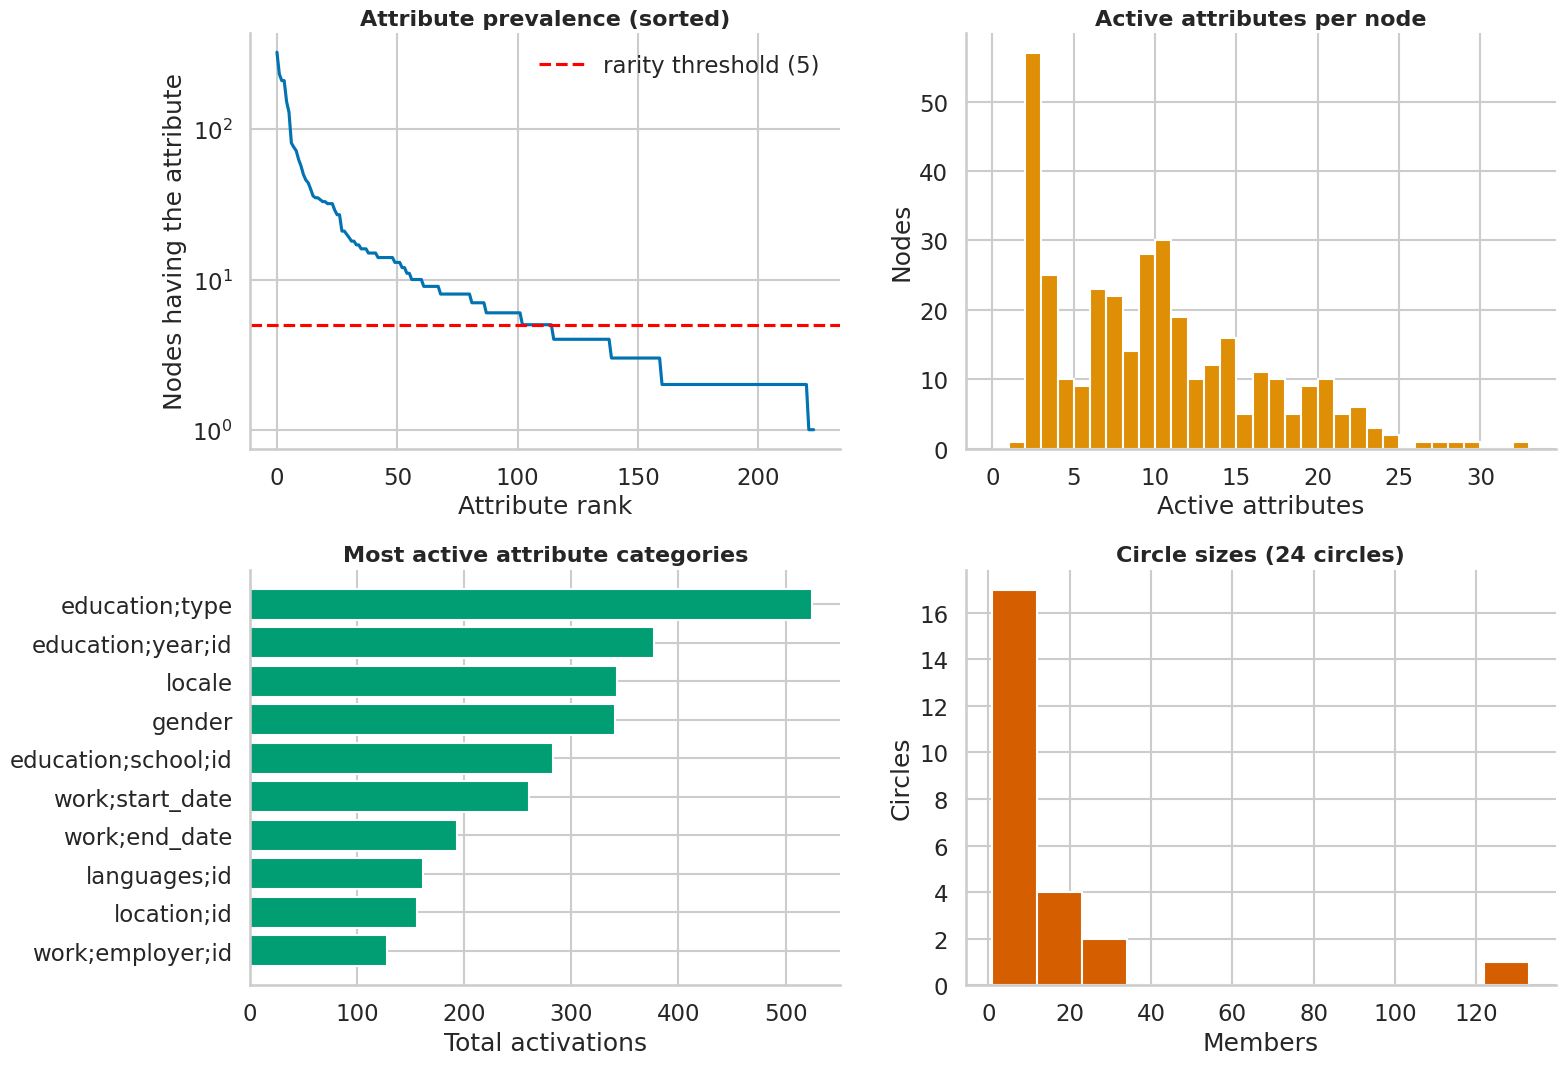

In [11]:
# ---- 8.2 Data-quality audit of the attribute matrix -------------------------------------------------------------
n, d = X_raw.shape
col_sum = X_raw.sum(0); row_sum = X_raw.sum(1)
uniq_rows, inv_idx, row_counts = np.unique(X_raw, axis=0, return_inverse=True, return_counts=True)
dup_rows = int((row_counts[inv_idx.ravel()] > 1).sum())
const_zero = int((col_sum == 0).sum()); const_one = int((col_sum == n).sum())
rare = int(((col_sum > 0) & (col_sum < CFG["MIN_NODES_PER_FEATURE"])).sum())
in_ego_edges = int(np.isin(node_ids, list(ego_G.nodes())).sum()); in_combined = int(np.isin(node_ids, NODES).sum())
labelled_nodes = int(np.isin(node_ids, list(node_circles.keys())).sum())
circ_sizes = np.array([len(v) for v in circles.values()]) if circles else np.array([0])
multi = sum(1 for v in node_circles.values() if len(v) > 1)

feat_audit = pd.DataFrame([
    ("Nodes (rows)", n), ("Attributes (columns)", d), ("Missing / NaN values", int(np.isnan(X_raw).sum())),
    ("Non-binary values", int((~np.isin(X_raw, [0, 1])).sum())), ("Duplicate node IDs", int(len(node_ids) - len(set(node_ids)))),
    ("Nodes sharing an identical attribute vector with another node", dup_rows),
    ("Nodes with zero active attributes", int((row_sum == 0).sum())),
    ("All-zero attributes (constant)", const_zero), ("All-one attributes (constant)", const_one),
    (f"Rare attributes (< {CFG['MIN_NODES_PER_FEATURE']} nodes)", rare),
    ("Mean active attributes per node", round(float(row_sum.mean()), 2)), ("Matrix density (share of 1s)", round(float(X_raw.mean()), 4)),
    ("Feature nodes found in ego-0 edge file", in_ego_edges), ("Feature nodes found in combined graph", in_combined),
    ("Circles", len(circles)), ("Nodes belonging to >= 1 circle", labelled_nodes), ("Nodes belonging to > 1 circle (overlap)", multi),
    ("Median circle size", float(np.median(circ_sizes))), ("Number of attribute categories", int(len(set(cats)))),
], columns=["check", "value"])
display(feat_audit); save_table(feat_audit, "feature_quality_audit")
assert np.isfinite(X_raw).all() and np.isin(X_raw, [0, 1]).all(), "Attribute matrix must be finite and binary"
assert len(set(node_ids)) == len(node_ids), "Duplicate node IDs in feature file"

# ---- 8.3 Feature EDA ---------------------------------------------------------------------------------------------------
cat_df = pd.DataFrame({"category": cats, "col_sum": col_sum}).groupby("category").agg(attributes=("col_sum", "size"), total_activations=("col_sum", "sum")).sort_values("total_activations", ascending=False)
fig, ax = plt.subplots(2, 2, figsize=(16, 11))
ax[0, 0].plot(np.sort(col_sum)[::-1], color=PAL[0]); ax[0, 0].axhline(CFG["MIN_NODES_PER_FEATURE"], color="red", ls="--", label=f"rarity threshold ({CFG['MIN_NODES_PER_FEATURE']})")
ax[0, 0].set(title="Attribute prevalence (sorted)", xlabel="Attribute rank", ylabel="Nodes having the attribute", yscale="log"); ax[0, 0].legend()
ax[0, 1].hist(row_sum, bins=range(0, int(row_sum.max()) + 2), color=PAL[1]); ax[0, 1].set(title="Active attributes per node", xlabel="Active attributes", ylabel="Nodes")
top_c = cat_df.head(10)[::-1]; ax[1, 0].barh(top_c.index, top_c.total_activations, color=PAL[2]); ax[1, 0].set(title="Most active attribute categories", xlabel="Total activations")
ax[1, 1].hist(circ_sizes, bins=min(12, max(3, len(circ_sizes))), color=PAL[3]); ax[1, 1].set(title=f"Circle sizes ({len(circles)} circles)", xlabel="Members", ylabel="Circles")
fig.tight_layout(); save_fig(fig, "fig05_feature_eda", "Attribute EDA for ego network 0: sparse, long-tailed attribute prevalence; most profiles have few active attributes; circles are small and overlapping.")
R["features_raw"] = {"n_nodes": n, "n_attributes": d, "missing": 0, "dup_rows": dup_rows, "zero_rows": int((row_sum == 0).sum()),
                     "const_zero": const_zero, "const_one": const_one, "rare": rare, "avg_active": float(row_sum.mean()),
                     "density": float(X_raw.mean()), "n_categories": int(len(set(cats))), "n_circles": len(circles),
                     "labelled_nodes": labelled_nodes, "labelled_pct": 100 * labelled_nodes / n, "overlap_nodes": multi,
                     "median_circle_size": float(np.median(circ_sizes)), "in_ego_edges": in_ego_edges, "in_combined": in_combined,
                     "load_seconds": t_feat["seconds"]}


### 8.4 Cleaning decisions (documented)
| Issue | Decision | Reason |
|---|---|---|
| Missing / non-binary values | none expected; assertion stops the run if found | K-Means needs a complete numeric matrix |
| Constant attributes (all 0 or all 1) | **removed** | zero variance, no information |
| Rare attributes (< `MIN_NODES_PER_FEATURE` nodes) | **removed** | too sparse to define clusters; mostly noise for Euclidean K-Means |
| Duplicate attribute vectors | **kept** | different people can legitimately share a profile; removing them would distort cluster sizes |
| Nodes with zero active attributes | **kept** (flagged) | they are real users; they form a legitimate "empty profile" group |

### 8.5 Feature extraction and feature engineering
- **Extraction:** attribute *categories* parsed from `featnames`; structural features computed from the graphs (degree inside ego-0, degree in the combined graph, local clustering coefficient, k-core number).
- **Engineering:** `n_active` (profile completeness), per-category activation counts, and four candidate **representations** compared in §9.3:
  1. `binary` — cleaned 0/1 matrix;
  2. `binary_std` — z-scored binary matrix (inflates rare attributes);
  3. `pca_binary` — PCA keeping `PCA_VARIANCE` of the variance (denoised; **pre-declared primary**);
  4. `engineered` — low-dimensional vector of `n_active`, category counts and structural features, z-scored.


,item,value
0,Attributes before cleaning,224.000000
1,Removed: constant,0.000000
2,Removed: rare (< 5 nodes),109.000000
3,Attributes after cleaning,115.000000
4,Nodes retained,347.000000
5,Engineered features,22.000000
6,PCA components for 90% variance,56.000000
7,Variance explained by first 2 components,0.217701


,count,mean,std,min,25%,50%,75%,max
node_id,347.0,174.000000,100.314505,1.0,87.5,174.0,260.5,347.0
n_active,347.0,8.743516,5.687979,1.0,4.0,8.0,12.0,27.0
cat::birthday,347.0,0.270893,0.445063,0.0,0.0,0.0,1.0,1.0
cat::education;concentration;id,347.0,0.282421,0.493667,0.0,0.0,0.0,1.0,2.0
cat::education;degree;id,347.0,0.060519,0.272693,0.0,0.0,0.0,0.0,2.0
cat::education;school;id,347.0,0.682997,0.601371,0.0,0.0,1.0,1.0,2.0
cat::education;type,347.0,1.512968,1.018175,0.0,1.0,2.0,2.0,3.0
cat::education;year;id,347.0,1.069164,1.096948,0.0,0.0,1.0,2.0,4.0
cat::gender,347.0,0.982709,0.130542,0.0,1.0,1.0,1.0,1.0
cat::hometown;id,347.0,0.074928,0.263655,0.0,0.0,0.0,0.0,1.0


Cleaning + feature engineering took 0.040 s


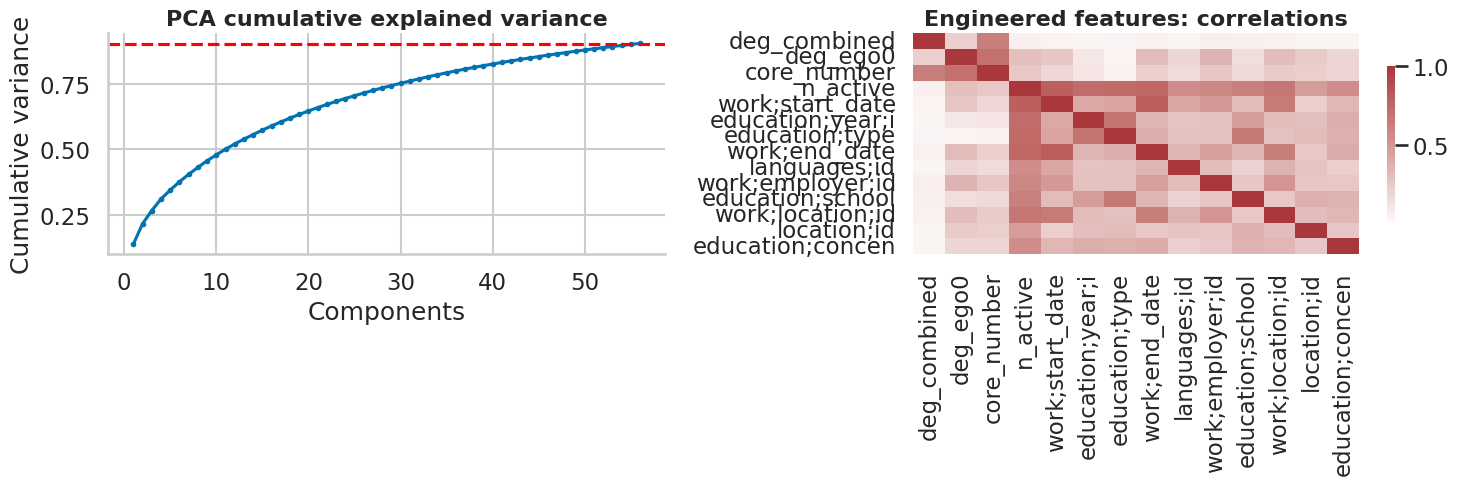

In [12]:
with timed("Clean attributes + feature engineering", "Drop constant/rare attributes, build structural/category features, PCA, scaling") as t_fe:
    keep = (col_sum >= CFG["MIN_NODES_PER_FEATURE"]) & (col_sum < n)
    X = X_raw[:, keep]; kept_ids = [fid for fid, k in zip(feat_ids, keep) if k]; kept_cats = cats[keep]
    removed_const = int(((col_sum == 0) | (col_sum == n)).sum()); removed_rare = int(((col_sum > 0) & (col_sum < CFG["MIN_NODES_PER_FEATURE"])).sum())

    # engineered low-dimensional features
    FE = pd.DataFrame({"node_id": node_ids, "n_active": X.sum(1)})
    for c in sorted(set(kept_cats)):
        FE[f"cat::{c}"] = X[:, kept_cats == c].sum(1)
    FE["deg_ego0"] = [ego_G.degree(v) if v in ego_G else 0 for v in node_ids]
    FE["deg_combined"] = [G.degree(v) if v in G else 0 for v in node_ids]
    FE["clustering"] = [clustering.get(v, 0.0) for v in node_ids]
    FE["core_number"] = [core.get(v, 0) for v in node_ids]
    eng_cols = [c for c in FE.columns if c != "node_id"]
    X_eng = StandardScaler().fit_transform(FE[eng_cols].values.astype(float))

    X_std = StandardScaler().fit_transform(X)
    pca_full = PCA(n_components=CFG["PCA_VARIANCE"], svd_solver="full", random_state=SEED).fit(X)
    X_pca = pca_full.transform(X)

REPS = {"binary": X, "binary_std": X_std, "pca_binary": X_pca, "engineered": X_eng}
assert CFG["PRIMARY_REPRESENTATION"] in REPS
X_primary = REPS[CFG["PRIMARY_REPRESENTATION"]]
save_table(FE, "engineered_features")
clean_summary = pd.DataFrame([
    ("Attributes before cleaning", d), ("Removed: constant", removed_const), (f"Removed: rare (< {CFG['MIN_NODES_PER_FEATURE']} nodes)", removed_rare),
    ("Attributes after cleaning", X.shape[1]), ("Nodes retained", X.shape[0]), ("Engineered features", len(eng_cols)),
    (f"PCA components for {CFG['PCA_VARIANCE']:.0%} variance", pca_full.n_components_),
    ("Variance explained by first 2 components", float(pca_full.explained_variance_ratio_[:2].sum())),
], columns=["item", "value"])
display(clean_summary); save_table(clean_summary, "feature_cleaning_summary")
display(FE.describe().T.head(12))
R["features"] = {"attributes_before": d, "removed_const": removed_const, "removed_rare": removed_rare, "attributes_after": int(X.shape[1]),
                 "engineered_features": len(eng_cols), "pca_components": int(pca_full.n_components_), "pca_variance": float(CFG["PCA_VARIANCE"]),
                 "pca_var_2": float(pca_full.explained_variance_ratio_[:2].sum()), "fe_seconds": t_fe["seconds"],
                 "primary_representation": CFG["PRIMARY_REPRESENTATION"]}
print(f"Cleaning + feature engineering took {t_fe['seconds']:.3f} s")

fig, ax = plt.subplots(1, 2, figsize=(15, 5.2))
ax[0].plot(np.arange(1, len(pca_full.explained_variance_ratio_) + 1), np.cumsum(pca_full.explained_variance_ratio_), marker="o", ms=3, color=PAL[0])
ax[0].axhline(CFG["PCA_VARIANCE"], color="red", ls="--"); ax[0].set(title="PCA cumulative explained variance", xlabel="Components", ylabel="Cumulative variance")
corr = FE[eng_cols].corr(); top_cols = FE[eng_cols].var().sort_values(ascending=False).head(14).index
sns.heatmap(FE[top_cols].corr(), cmap="vlag", center=0, ax=ax[1], cbar_kws={"shrink": 0.7}, xticklabels=[c.replace("cat::", "")[:16] for c in top_cols], yticklabels=[c.replace("cat::", "")[:16] for c in top_cols])
ax[1].set_title("Engineered features: correlations"); fig.tight_layout()
save_fig(fig, "fig06_feature_engineering", "Feature engineering: PCA variance retention (left) and correlation structure of the engineered category/structural features (right).")


## 9. Algorithm 2 — K-Means clustering

### 9.1 Method, metrics and selection rule

**Implementation.** A from-scratch Lloyd's algorithm with **k-means++ seeding**, several restarts, empty-cluster repair and an inertia history (for the convergence plot). It is validated on synthetic blobs and then cross-checked against `sklearn.cluster.KMeans` on the real data. The *K* sweep uses scikit-learn (same objective, faster) with `n_init` restarts.

**Metrics (all reported, none called "accuracy" except the matched clustering accuracy)**
- *Internal:* inertia (elbow), **silhouette** (−1…1, higher is better), **Davies–Bouldin** (lower is better), **Calinski–Harabasz** (higher is better).
- *Stability:* mean pairwise ARI between single-start runs with different seeds (1 = identical partitions).
- *External (vs. social circles):* ARI, NMI, homogeneity/completeness, purity and **Hungarian-matched clustering accuracy**, always with the **majority-class baseline** and a **label-permutation baseline**.
- *Runtime:* model fit time and silhouette time.

**K-selection rule (pre-declared):** the *K* with the highest silhouette among values whose smallest cluster has at least `MIN_CLUSTER_SIZE` nodes. The elbow, Davies–Bouldin and Calinski–Harabasz choices are reported for comparison; external labels are **not** used to choose *K*.


In [13]:
def kmeanspp_init(X, k, rng):
    n = X.shape[0]; centers = [X[rng.integers(n)]]
    d2 = ((X - centers[0]) ** 2).sum(1)
    for _ in range(1, k):
        probs = d2 / d2.sum() if d2.sum() > 0 else np.full(n, 1 / n)
        centers.append(X[rng.choice(n, p=probs)])
        d2 = np.minimum(d2, ((X - centers[-1]) ** 2).sum(1))
    return np.array(centers)

def sq_dists(X, C):
    return np.maximum((X ** 2).sum(1)[:, None] - 2 * X @ C.T + (C ** 2).sum(1)[None, :], 0)

def kmeans_scratch(X, k, n_init=10, max_iter=300, tol=1e-8, seed=0):
    """Lloyd's algorithm + k-means++ seeding. Returns the best of n_init runs."""
    rng = np.random.default_rng(seed); best = None
    for _ in range(n_init):
        C = kmeanspp_init(X, k, rng); hist = []
        for it in range(1, max_iter + 1):
            D = sq_dists(X, C); labels = D.argmin(1); inertia = float(D[np.arange(len(X)), labels].sum()); hist.append(inertia)
            newC = C.copy()
            for j in range(k):
                m = labels == j
                if m.any(): newC[j] = X[m].mean(0)
                else: newC[j] = X[D.min(1).argmax()]                  # empty-cluster repair: farthest point
            shift = float(((newC - C) ** 2).sum()); C = newC
            if shift <= tol: break
        D = sq_dists(X, C); labels = D.argmin(1); inertia = float(D[np.arange(len(X)), labels].sum())
        if best is None or inertia < best["inertia"]:
            best = {"labels": labels, "centers": C, "inertia": inertia, "n_iter": it, "history": hist}
    return best

# ---- Validation on synthetic blobs with known structure ----------------------------------------------------
from sklearn.datasets import make_blobs
Xb, yb = make_blobs(n_samples=600, centers=4, cluster_std=0.6, random_state=SEED)
tb = kmeans_scratch(Xb, 4, n_init=5, seed=SEED)
blob_ari = adjusted_rand_score(yb, tb["labels"])
assert blob_ari > 0.95, f"from-scratch K-Means failed the blob test (ARI={blob_ari:.3f})"
print(f"Blob validation passed: ARI vs true blobs = {blob_ari:.3f}, converged in {tb['n_iter']} iterations")
R["kmeans_validation"] = {"blob_ari": float(blob_ari)}


Blob validation passed: ARI vs true blobs = 1.000, converged in 2 iterations


In [14]:
# ---- Reference labels derived from circles (nodes may belong to several circles) -------------------------------
circle_size = {c: len(m) for c, m in circles.items()}
ref_first   = {v: lst[0] for v, lst in node_circles.items()}                                    # first listed circle
ref_largest = {v: max(lst, key=lambda c: (circle_size[c], c)) for v, lst in node_circles.items()}  # largest circle containing node
eval_mask = np.array([v in ref_first for v in node_ids])
REF = {"first": np.array([ref_first[v] for v in node_ids[eval_mask]]),
       "largest": np.array([ref_largest[v] for v in node_ids[eval_mask]])}
print(f"Nodes with a circle label: {eval_mask.sum()} / {len(node_ids)} | classes: first={len(set(REF['first']))}, largest={len(set(REF['largest']))}")

def contingency(pred, ref):
    pv, pi = np.unique(pred, return_inverse=True); rv, ri = np.unique(ref, return_inverse=True)
    C = np.zeros((len(pv), len(rv)), dtype=int); np.add.at(C, (pi, ri), 1)
    return C, pv, rv

def external_eval(pred, ref):
    """Agreement with reference labels. matched_accuracy uses the optimal one-to-one cluster->label assignment."""
    if len(ref) == 0 or len(set(pred)) < 1:
        return {k: np.nan for k in ["ari", "nmi", "homogeneity", "completeness", "v_measure", "purity", "matched_accuracy", "majority_baseline", "n_eval"]}
    C, _, _ = contingency(pred, ref); tot = C.sum()
    r, c = linear_sum_assignment(-C)
    h, comp, v = homogeneity_completeness_v_measure(ref, pred)
    return {"ari": adjusted_rand_score(ref, pred), "nmi": normalized_mutual_info_score(ref, pred), "homogeneity": h, "completeness": comp,
            "v_measure": v, "purity": C.max(1).sum() / tot, "matched_accuracy": C[r, c].sum() / tot,
            "majority_baseline": C.sum(0).max() / tot, "n_eval": int(tot)}

def interpret_silhouette(s):      # Kaufman & Rousseeuw (1990) rule of thumb
    if s > 0.70: return "strong structure"
    if s > 0.50: return "reasonable structure"
    if s > 0.25: return "weak structure"
    return "no substantial structure"

def kmeans_sweep(Xrep, ks, scheme="first", stability=True, n_init=None):
    n_init = n_init or CFG["N_INIT"]; rows, models = [], {}
    sil_idx = np.arange(len(Xrep))
    if len(Xrep) > 5000: sil_idx = np.random.default_rng(SEED).choice(len(Xrep), 5000, replace=False)
    for k in ks:
        t0 = time.perf_counter(); km = KMeans(n_clusters=k, n_init=n_init, random_state=SEED, max_iter=300).fit(Xrep)
        fit_s = time.perf_counter() - t0; lab = km.labels_; cnt = np.bincount(lab, minlength=k)
        t0 = time.perf_counter(); sil = silhouette_score(Xrep[sil_idx], lab[sil_idx]) if len(set(lab[sil_idx])) > 1 else np.nan
        sil_s = time.perf_counter() - t0
        row = {"k": k, "inertia": km.inertia_, "silhouette": sil, "davies_bouldin": davies_bouldin_score(Xrep, lab),
               "calinski_harabasz": calinski_harabasz_score(Xrep, lab), "n_iter": int(km.n_iter_), "fit_time_s": fit_s,
               "silhouette_time_s": sil_s, "min_cluster": int(cnt.min()), "max_cluster": int(cnt.max())}
        if stability:
            labs = [KMeans(n_clusters=k, n_init=1, random_state=SEED + 1 + s).fit_predict(Xrep) for s in range(CFG["STABILITY_SEEDS"])]
            aris = [adjusted_rand_score(a, b) for i, a in enumerate(labs) for b in labs[i + 1:]]
            row.update({"stability_ari": float(np.mean(aris)), "stability_ari_std": float(np.std(aris))})
        ext = external_eval(lab[eval_mask], REF[scheme])
        row.update({"ext_ari": ext["ari"], "ext_nmi": ext["nmi"], "ext_matched_acc": ext["matched_accuracy"], "ext_majority": ext["majority_baseline"]})
        rows.append(row); models[k] = km
    return pd.DataFrame(rows), models

def elbow_k(ks, inertia):
    """Knee = point farthest from the chord joining the first and last points of the normalised curve."""
    x = (np.array(ks) - ks[0]) / (ks[-1] - ks[0]); y = (np.array(inertia) - min(inertia)) / (max(inertia) - min(inertia))
    return int(ks[int(np.argmax(np.abs(x + y - 1) / np.sqrt(2)))])


Nodes with a circle label: 286 / 347 | classes: first=24, largest=21


### 9.2 K sweep on the primary representation and K selection
Each K is fitted with multiple restarts; internal metrics, seed stability, runtime and (diagnostic only) agreement with circles are tabulated. K is chosen by the pre-declared rule.


In [15]:
KS = list(range(CFG["K_MIN"], min(CFG["K_MAX"], len(X_primary) - 1) + 1))
with timed("K-Means sweep (primary representation)", f"K={KS[0]}..{KS[-1]}, n_init={CFG['N_INIT']}, stability, external metrics") as t_sweep:
    sweep_df, MODELS = kmeans_sweep(X_primary, KS)
display(sweep_df.round(4)); save_table(sweep_df, "kmeans_sweep_primary")

valid = sweep_df[(sweep_df.min_cluster >= CFG["MIN_CLUSTER_SIZE"]) & sweep_df.silhouette.notna()]
if valid.empty: valid = sweep_df.dropna(subset=["silhouette"])
BEST_K = int(valid.loc[valid.silhouette.idxmax(), "k"])
choices = {"silhouette": BEST_K, "elbow": elbow_k(KS, sweep_df.inertia.tolist()),
           "davies_bouldin": int(sweep_df.loc[sweep_df.davies_bouldin.idxmin(), "k"]),
           "calinski_harabasz": int(sweep_df.loc[sweep_df.calinski_harabasz.idxmax(), "k"]),
           "stability": int(sweep_df.loc[sweep_df.stability_ari.idxmax(), "k"])}
choice_df = pd.DataFrame([{"criterion": k, "preferred_k": v} for k, v in choices.items()]); display(choice_df); save_table(choice_df, "kmeans_k_criteria")
BEST_MODEL = MODELS[BEST_K]; LABELS = BEST_MODEL.labels_
brow = sweep_df[sweep_df.k == BEST_K].iloc[0]
print(f"Selected K = {BEST_K} (rule: {CFG['K_SELECTION_RULE']}). Silhouette = {brow.silhouette:.4f} -> {interpret_silhouette(brow.silhouette)} (Kaufman & Rousseeuw scale).")
R["kmeans"] = {"best_k": BEST_K, "k_range": [KS[0], KS[-1]], "silhouette": float(brow.silhouette), "silhouette_label": interpret_silhouette(brow.silhouette),
               "davies_bouldin": float(brow.davies_bouldin), "calinski_harabasz": float(brow.calinski_harabasz), "inertia": float(brow.inertia),
               "n_iter": int(brow.n_iter), "fit_time_s": float(brow.fit_time_s), "silhouette_time_s": float(brow.silhouette_time_s),
               "stability_ari": float(brow.stability_ari), "min_cluster": int(brow.min_cluster), "max_cluster": int(brow.max_cluster),
               "criteria": choices, "n_init": CFG["N_INIT"], "sweep_seconds": t_sweep["seconds"], "representation": CFG["PRIMARY_REPRESENTATION"],
               "dims": int(X_primary.shape[1])}


,k,inertia,silhouette,davies_bouldin,calinski_harabasz,n_iter,fit_time_s,silhouette_time_s,min_cluster,max_cluster,stability_ari,stability_ari_std,ext_ari,ext_nmi,ext_matched_acc,ext_majority
0,2,1635.8272,0.1726,2.7121,43.3226,11,0.0581,0.0071,145,202,0.8763,0.1380,0.0166,0.1104,0.3147,0.4301
1,3,1518.5066,0.1046,2.4654,36.5560,12,0.0592,0.0044,95,129,0.4187,0.2028,0.0215,0.1331,0.2657,0.4301
2,4,1445.7001,0.1111,2.7838,31.2815,14,0.0445,0.0044,64,104,0.5484,0.1880,0.0145,0.1317,0.2343,0.4301
3,5,1396.0079,0.0868,2.5901,27.2689,9,0.0481,0.0043,44,114,0.5432,0.1969,0.0245,0.1400,0.2413,0.4301
4,6,1353.8195,0.0995,2.7271,24.5544,13,0.0940,0.0102,36,77,0.5341,0.1785,0.0133,0.1726,0.2168,0.4301
5,7,1319.1132,0.1057,2.6627,22.4297,13,0.0857,0.0106,11,69,0.5291,0.1364,0.0242,0.1814,0.2273,0.4301
6,8,1291.5633,0.1109,2.8832,20.6108,8,0.0900,0.0113,23,65,0.5891,0.1094,0.0175,0.2027,0.2308,0.4301
7,9,1270.8909,0.1145,2.6426,18.9610,7,0.0844,0.0135,5,60,0.5875,0.1196,0.0211,0.2010,0.2308,0.4301
8,10,1249.0505,0.1160,2.6535,17.7529,11,0.0932,0.0108,6,69,0.5703,0.1026,0.0103,0.2167,0.2483,0.4301
9,11,1231.4030,0.1183,2.5471,16.6401,10,0.0996,0.0047,2,60,0.5682,0.0977,0.0037,0.2053,0.2168,0.4301


,criterion,preferred_k
0,silhouette,2
1,elbow,5
2,davies_bouldin,3
3,calinski_harabasz,2
4,stability,2


Selected K = 2 (rule: max silhouette among K with smallest cluster >= MIN_CLUSTER_SIZE). Silhouette = 0.1726 -> no substantial structure (Kaufman & Rousseeuw scale).


### 9.3 Representation ablation
The same sweep is repeated for four feature representations to show how much feature engineering matters. The primary representation is **not** switched after seeing external scores.


In [16]:
# ---- Representation ablation: same pipeline, four feature representations ---------------------------------------
abl_rows = []
with timed("Representation ablation", "K-Means sweep for every representation (stability skipped)") as t_abl:
    for name, Xr in REPS.items():
        sdf, _ = kmeans_sweep(Xr, KS, stability=False, n_init=10)
        ok = sdf[(sdf.min_cluster >= CFG["MIN_CLUSTER_SIZE"]) & sdf.silhouette.notna()]
        ok = ok if not ok.empty else sdf.dropna(subset=["silhouette"])
        b = ok.loc[ok.silhouette.idxmax()]; at_primary = sdf[sdf.k == BEST_K].iloc[0]
        abl_rows.append({"representation": name, "dims": Xr.shape[1], "best_k_by_silhouette": int(b.k), "silhouette": b.silhouette,
                         "davies_bouldin": b.davies_bouldin, "ext_ari_at_best_k": b.ext_ari, "ext_nmi_at_best_k": b.ext_nmi,
                         f"ext_ari_at_K={BEST_K}": at_primary.ext_ari, f"ext_nmi_at_K={BEST_K}": at_primary.ext_nmi,
                         f"matched_acc_at_K={BEST_K}": at_primary.ext_matched_acc})
abl_df = pd.DataFrame(abl_rows); display(abl_df.round(4)); save_table(abl_df, "kmeans_representation_ablation")
R["ablation"] = {"rows": [{k: to_py(v) for k, v in r.items()} for r in abl_rows], "seconds": t_abl["seconds"]}
print("Note: silhouette values from different feature spaces are not directly comparable; ARI/NMI against circles are.")


,representation,dims,best_k_by_silhouette,silhouette,davies_bouldin,ext_ari_at_best_k,ext_nmi_at_best_k,ext_ari_at_K=2,ext_nmi_at_K=2,matched_acc_at_K=2
0,binary,115,2,0.1606,2.8646,0.0217,0.1174,0.0217,0.1174,0.3182
1,binary_std,115,2,0.2843,3.8870,-0.0405,0.0595,-0.0405,0.0595,0.3287
2,pca_binary,56,2,0.1726,2.7121,0.0166,0.1104,0.0166,0.1104,0.3147
3,engineered,22,2,0.2830,1.7658,-0.0351,0.0679,-0.0351,0.0679,0.3007


Note: silhouette values from different feature spaces are not directly comparable; ARI/NMI against circles are.


### 9.4 Final model: cross-check, external evaluation and baselines
The from-scratch K-Means is compared with scikit-learn; agreement with circles is measured with ARI, NMI, purity and Hungarian-matched accuracy against a majority baseline and a permutation test; Louvain communities give a structural reference.


In [17]:
# ---- Final model: scratch vs scikit-learn, external evaluation, permutation test, structure comparison ----------------
with timed("From-scratch K-Means (selected K)", f"Lloyd + k-means++, n_init={CFG['N_INIT']}") as t_scr:
    SCR = kmeans_scratch(X_primary, BEST_K, n_init=CFG["N_INIT"], seed=SEED)
t0 = time.perf_counter(); SK = KMeans(n_clusters=BEST_K, n_init=CFG["N_INIT"], random_state=SEED).fit(X_primary); sk_s = time.perf_counter() - t0
gap = abs(SCR["inertia"] - SK.inertia_) / SK.inertia_ * 100
part_ari = adjusted_rand_score(SK.labels_, SCR["labels"])
cmp_df = pd.DataFrame([{"implementation": "From scratch (Lloyd + k-means++)", "inertia": SCR["inertia"], "iterations": SCR["n_iter"], "time_s": t_scr["seconds"]},
                       {"implementation": "scikit-learn KMeans", "inertia": SK.inertia_, "iterations": SK.n_iter_, "time_s": sk_s}])
display(cmp_df); save_table(cmp_df, "kmeans_scratch_vs_sklearn")
print(f"Inertia gap: {gap:.3f}% | agreement between the two partitions (ARI): {part_ari:.3f}")
R["kmeans"].update({"scratch_inertia": SCR["inertia"], "sklearn_inertia": float(SK.inertia_), "inertia_gap_pct": float(gap), "partition_ari": float(part_ari),
                    "scratch_time_s": t_scr["seconds"], "sklearn_time_s": sk_s, "scratch_iter": int(SCR["n_iter"])})

# ---- External evaluation (both labelling schemes) ---------------------------------------------------------------------
ext_rows = []
for scheme in ("first", "largest"):
    e = external_eval(LABELS[eval_mask], REF[scheme]); e.update({"labelling_scheme": scheme, "n_reference_classes": len(set(REF[scheme]))}); ext_rows.append(e)
ext_df = pd.DataFrame(ext_rows)[["labelling_scheme", "n_eval", "n_reference_classes", "ari", "nmi", "homogeneity", "completeness", "v_measure", "purity", "matched_accuracy", "majority_baseline"]]
display(ext_df.round(4)); save_table(ext_df, "kmeans_external_evaluation")

# ---- Permutation baseline: shuffle reference labels and recompute --------------------------------------------------------
rng = np.random.default_rng(SEED); perm = {"ari": [], "matched_accuracy": [], "nmi": []}
with timed("Permutation test", f"{CFG['PERMUTATION_TESTS']} label shuffles") as t_perm:
    for _ in range(CFG["PERMUTATION_TESTS"]):
        e = external_eval(LABELS[eval_mask], rng.permutation(REF["first"]))
        for k_ in perm: perm[k_].append(e[k_])
obs = ext_rows[0]; perm_rows = []
for m_ in ("ari", "nmi", "matched_accuracy"):
    arr = np.array(perm[m_]); p = (1 + (arr >= obs[m_]).sum()) / (1 + len(arr))
    perm_rows.append({"metric": m_, "observed": obs[m_], "permuted_mean": arr.mean(), "permuted_95th_pct": np.percentile(arr, 95), "p_value": p})
perm_df = pd.DataFrame(perm_rows); display(perm_df.round(4)); save_table(perm_df, "kmeans_permutation_test")

# ---- Do attribute clusters reflect network structure? (Louvain on the ego network) ----------------------------------------
louv = {}
try:
    sub_ego = ego_G.subgraph([v for v in node_ids if v in ego_G]).copy()
    comms = nx.community.louvain_communities(sub_ego, seed=SEED)
    c_of = {v: i for i, cset in enumerate(comms) for v in cset}
    have = np.array([v in c_of for v in node_ids]); lab_l = np.array([c_of[v] for v in node_ids[have]])
    louv = {"n_communities": len(comms), "nmi_vs_kmeans": normalized_mutual_info_score(lab_l, LABELS[have]), "ari_vs_kmeans": adjusted_rand_score(lab_l, LABELS[have])}
    ev = external_eval(lab_l[np.isin(node_ids[have], list(ref_first))], np.array([ref_first[v] for v in node_ids[have] if v in ref_first]))
    louv.update({"ari_vs_circles": ev["ari"], "nmi_vs_circles": ev["nmi"]})
    display(pd.DataFrame([louv]).round(4))
except Exception as ex:
    print("Louvain comparison skipped:", ex)

R["external"] = {"first": {k: to_py(v) for k, v in ext_rows[0].items()}, "largest": {k: to_py(v) for k, v in ext_rows[1].items()},
                 "perm": {r["metric"]: {k: to_py(v) for k, v in r.items()} for r in perm_rows}, "louvain": {k: to_py(v) for k, v in louv.items()},
                 "perm_seconds": t_perm["seconds"]}


,implementation,inertia,iterations,time_s
0,From scratch (Lloyd + k-means++),1635.798314,8,0.042269
1,scikit-learn KMeans,1635.827164,11,0.025551


Inertia gap: 0.002% | agreement between the two partitions (ARI): 0.988


,labelling_scheme,n_eval,n_reference_classes,ari,nmi,homogeneity,completeness,v_measure,purity,matched_accuracy,majority_baseline
0,first,286,24,0.0166,0.1104,0.0727,0.2289,0.1104,0.4301,0.3147,0.4301
1,largest,286,21,0.0186,0.1129,0.0754,0.2243,0.1129,0.4650,0.3357,0.4650


,metric,observed,permuted_mean,permuted_95th_pct,p_value
0,ari,0.0166,0.0003,0.0110,0.0200
1,nmi,0.1104,0.0347,0.0479,0.0020
2,matched_accuracy,0.3147,0.2850,0.3077,0.0359


,n_communities,nmi_vs_kmeans,ari_vs_kmeans,ari_vs_circles,nmi_vs_circles
0,14,0.1254,0.0706,0.1564,0.394


### 9.5 Figures and cluster profiling
Poster-ready figures: model selection, PCA projection, silhouette plot, cluster profiles, clusters vs circles/network, convergence and ablation.


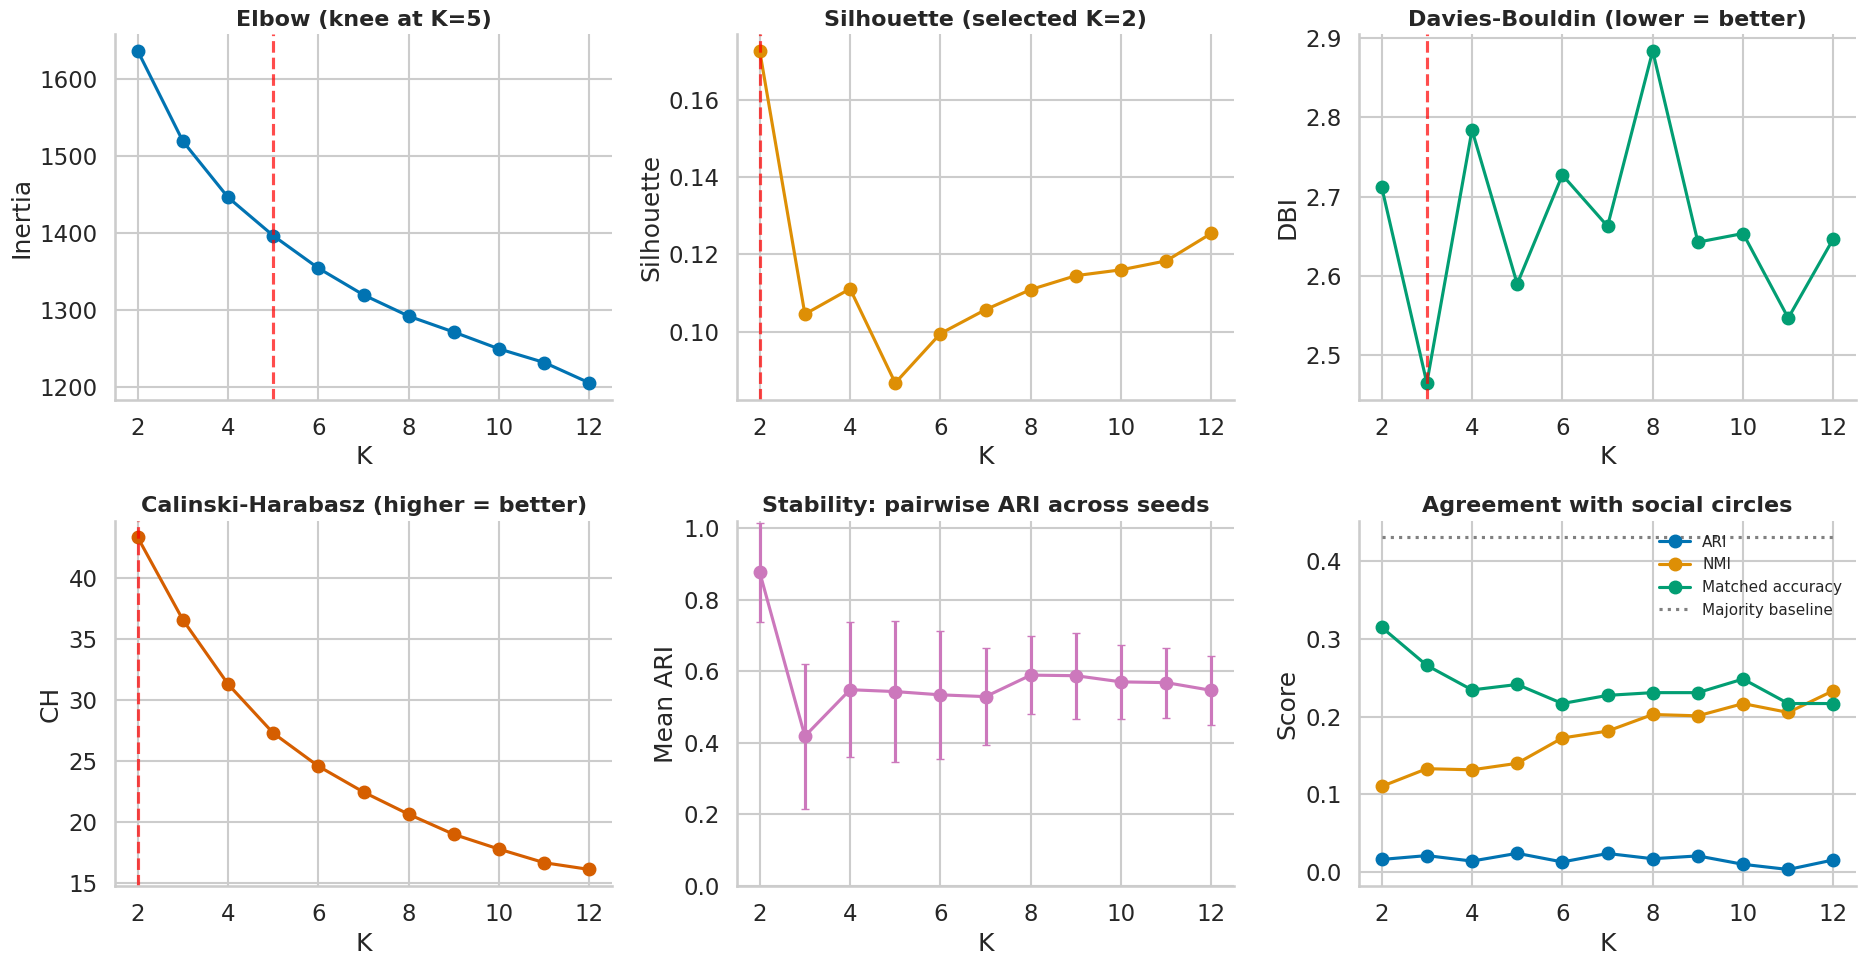

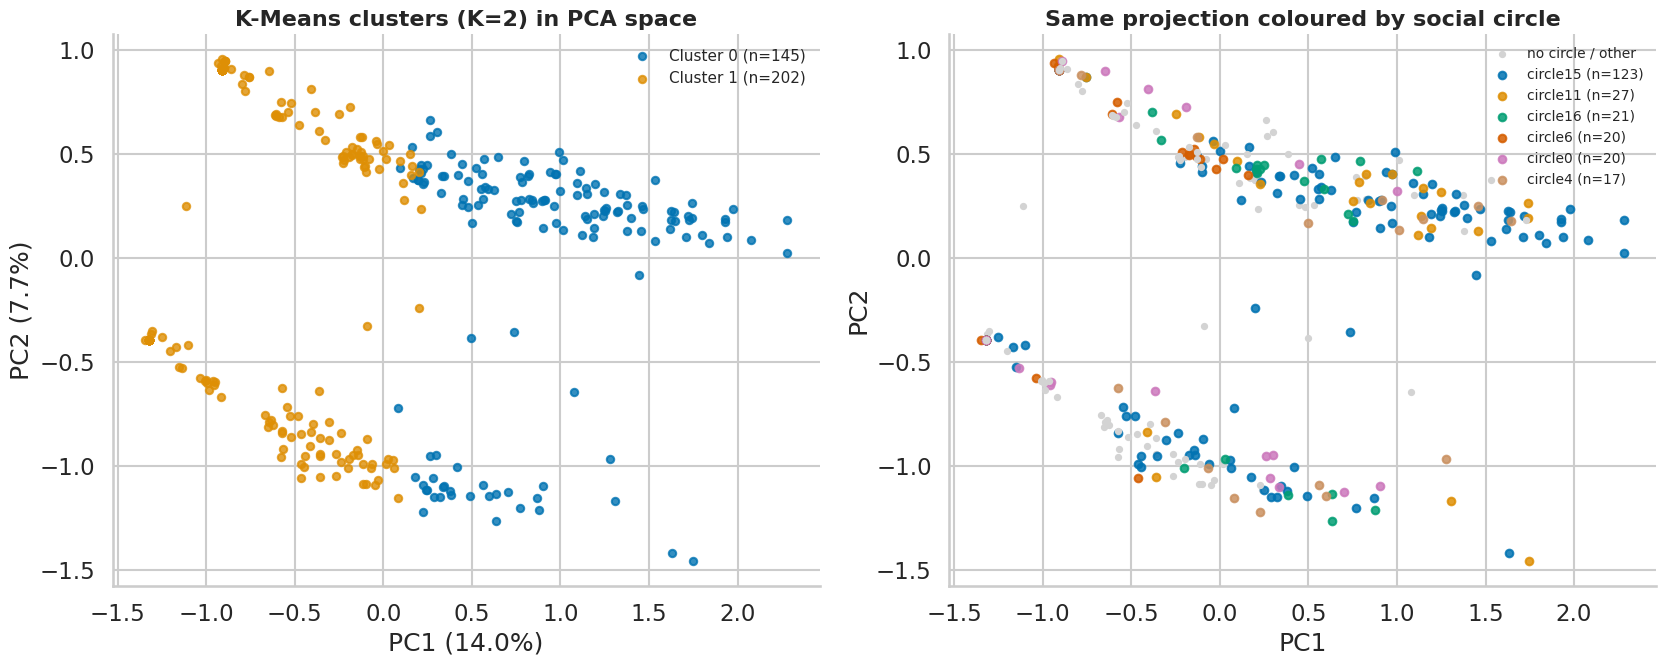

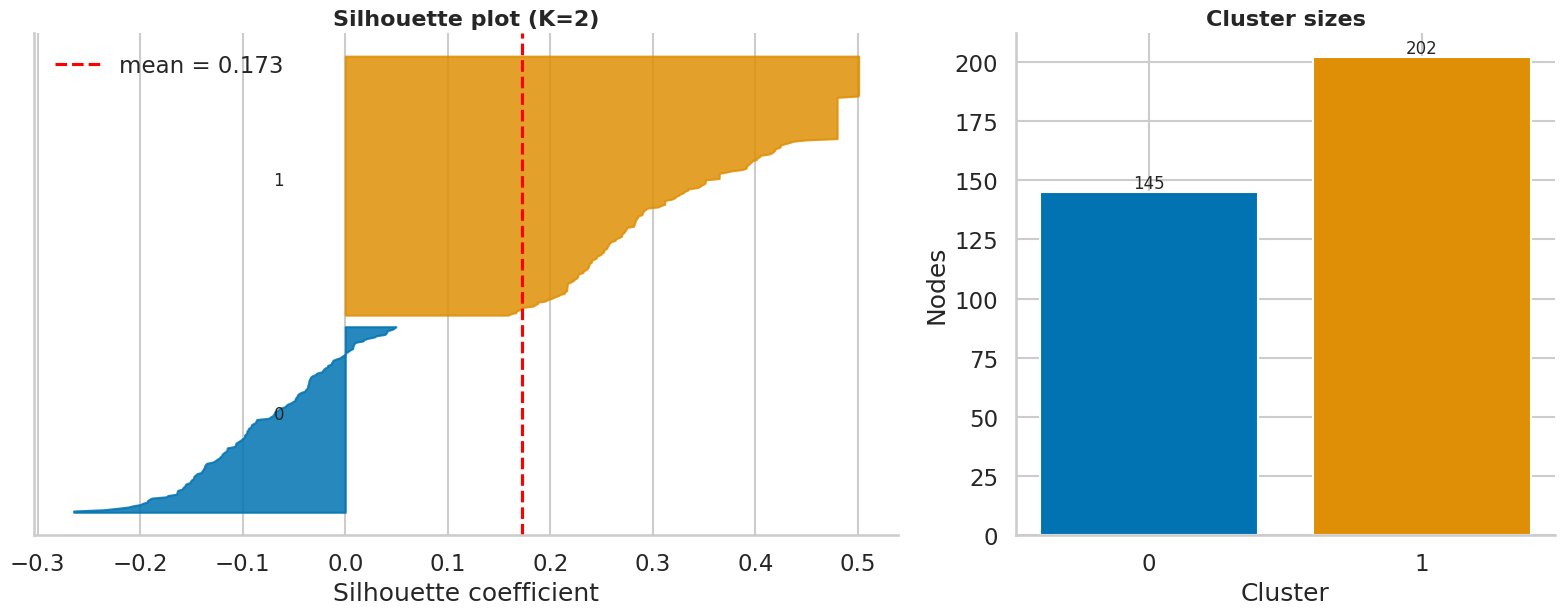

,cluster,size,attribute,prevalence_in_cluster,prevalence_elsewhere,difference
0,0,145,education;school;id#50,0.862,0.139,0.723
1,0,145,education;type#53,0.972,0.455,0.517
2,0,145,education;concentration;id#14,0.503,0.015,0.489
3,0,145,education;type#55,0.848,0.436,0.413
4,0,145,education;year;id#65,0.421,0.054,0.366
5,1,202,gender#77,0.495,0.207,0.288
6,1,202,hometown;id#81,0.074,0.000,0.074
7,1,202,education;school;id#39,0.069,0.000,0.069
8,1,202,education;school;id#45,0.059,0.000,0.059
9,1,202,education;school;id#38,0.040,0.000,0.040


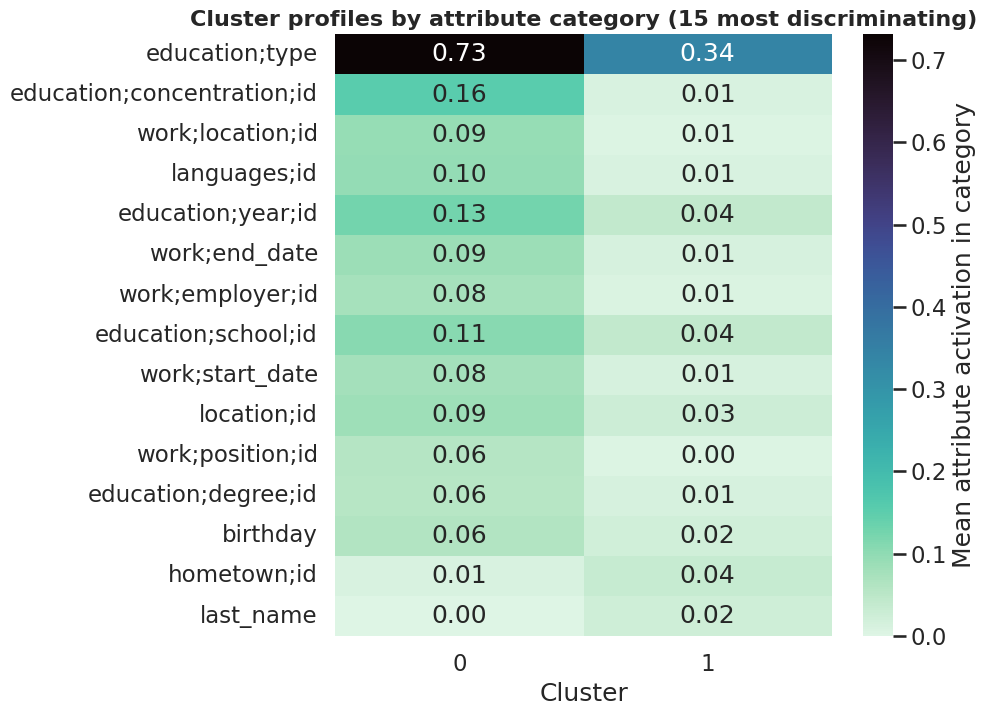

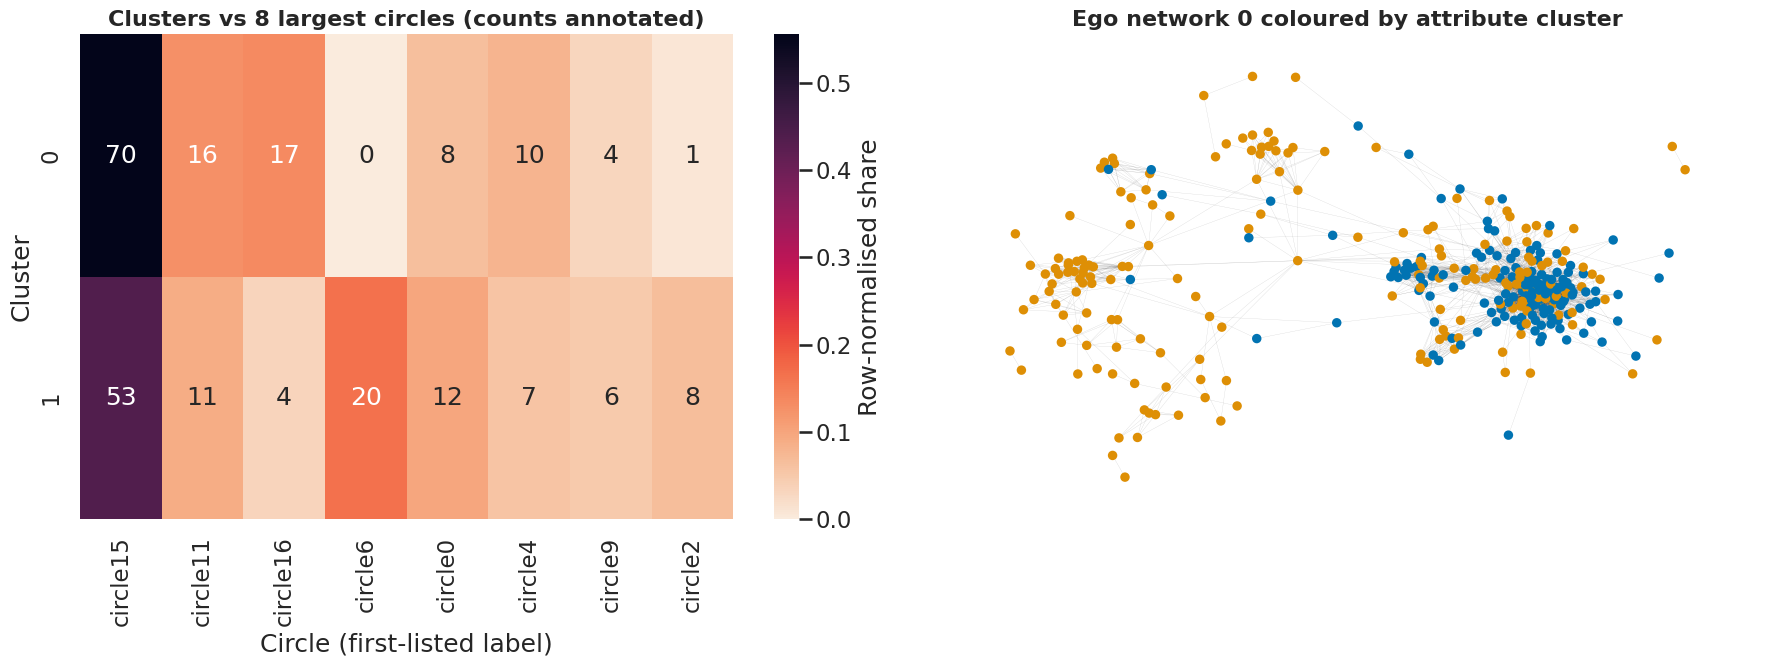

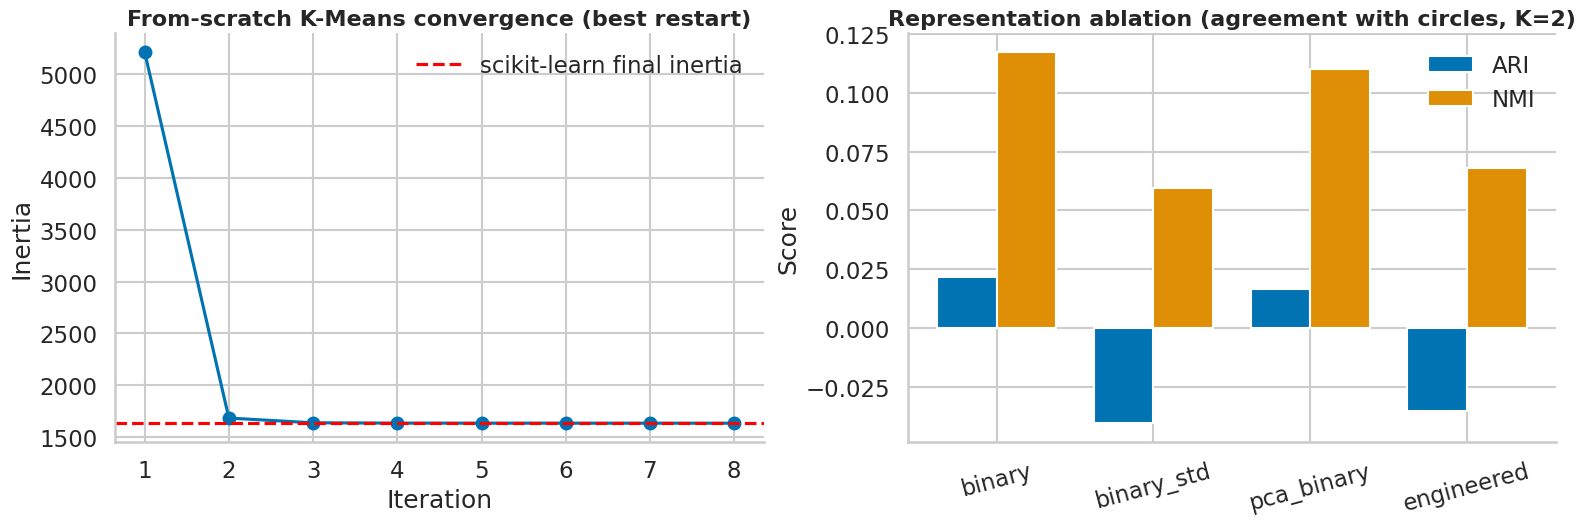

In [18]:
# ---- Figure: model selection panel -----------------------------------------------------------------------------------------
fig, ax = plt.subplots(2, 3, figsize=(19, 10))
def mark(a, k, col="red"): a.axvline(k, color=col, ls="--", alpha=0.7)
ax[0, 0].plot(sweep_df.k, sweep_df.inertia, marker="o", color=PAL[0]); mark(ax[0, 0], choices["elbow"]); ax[0, 0].set(title=f"Elbow (knee at K={choices['elbow']})", xlabel="K", ylabel="Inertia")
ax[0, 1].plot(sweep_df.k, sweep_df.silhouette, marker="o", color=PAL[1]); mark(ax[0, 1], BEST_K); ax[0, 1].set(title=f"Silhouette (selected K={BEST_K})", xlabel="K", ylabel="Silhouette")
ax[0, 2].plot(sweep_df.k, sweep_df.davies_bouldin, marker="o", color=PAL[2]); mark(ax[0, 2], choices["davies_bouldin"]); ax[0, 2].set(title="Davies-Bouldin (lower = better)", xlabel="K", ylabel="DBI")
ax[1, 0].plot(sweep_df.k, sweep_df.calinski_harabasz, marker="o", color=PAL[3]); mark(ax[1, 0], choices["calinski_harabasz"]); ax[1, 0].set(title="Calinski-Harabasz (higher = better)", xlabel="K", ylabel="CH")
ax[1, 1].errorbar(sweep_df.k, sweep_df.stability_ari, yerr=sweep_df.stability_ari_std, marker="o", color=PAL[4], capsize=3); ax[1, 1].set(title="Stability: pairwise ARI across seeds", xlabel="K", ylabel="Mean ARI", ylim=(0, 1.02))
for col, lab_, c_ in [("ext_ari", "ARI", PAL[0]), ("ext_nmi", "NMI", PAL[1]), ("ext_matched_acc", "Matched accuracy", PAL[2])]:
    ax[1, 2].plot(sweep_df.k, sweep_df[col], marker="o", label=lab_, color=c_)
ax[1, 2].plot(sweep_df.k, sweep_df.ext_majority, ls=":", color="gray", label="Majority baseline"); ax[1, 2].set(title="Agreement with social circles", xlabel="K", ylabel="Score"); ax[1, 2].legend(fontsize=11)
fig.tight_layout(); save_fig(fig, "fig07_kmeans_model_selection", "K-Means model selection over K: elbow, silhouette, Davies-Bouldin, Calinski-Harabasz, seed stability and (diagnostic only) agreement with circles.")

# ---- Figure: PCA projection coloured by cluster and by circle ----------------------------------------------------------------
pca2 = PCA(n_components=2, random_state=SEED).fit(X); Z = pca2.transform(X)
fig, ax = plt.subplots(1, 2, figsize=(17, 7))
for c in range(BEST_K):
    m = LABELS == c; ax[0].scatter(Z[m, 0], Z[m, 1], s=28, alpha=0.8, color=sns.color_palette("colorblind", max(BEST_K, 3))[c], label=f"Cluster {c} (n={m.sum()})")
ax[0].set(title=f"K-Means clusters (K={BEST_K}) in PCA space", xlabel=f"PC1 ({pca2.explained_variance_ratio_[0]:.1%})", ylabel=f"PC2 ({pca2.explained_variance_ratio_[1]:.1%})"); ax[0].legend(fontsize=11)
top_circ = [c for c, _ in Counter(REF["first"]).most_common(6)]; circ_lab = np.array([ref_first.get(v, "none") for v in node_ids])
ax[1].scatter(Z[circ_lab == "none", 0], Z[circ_lab == "none", 1], s=14, color="lightgray", label="no circle / other")
for i, c in enumerate(top_circ):
    m = circ_lab == c; ax[1].scatter(Z[m, 0], Z[m, 1], s=30, alpha=0.85, color=PAL[i], label=f"{c} (n={m.sum()})")
m = ~np.isin(circ_lab, top_circ + ["none"]); ax[1].scatter(Z[m, 0], Z[m, 1], s=14, color="lightgray")
ax[1].set(title="Same projection coloured by social circle", xlabel="PC1", ylabel="PC2"); ax[1].legend(fontsize=10)
fig.tight_layout(); save_fig(fig, "fig08_kmeans_pca_projection", "Two-dimensional PCA projection of the cleaned attribute matrix, coloured by K-Means cluster (left) and by the six largest first-listed circles (right).")

# ---- Figure: silhouette plot + cluster sizes ------------------------------------------------------------------------------------
ss = silhouette_samples(X_primary, LABELS); fig, ax = plt.subplots(1, 2, figsize=(16, 6.5), gridspec_kw={"width_ratios": [1.6, 1]})
y0 = 0; cols = sns.color_palette("colorblind", max(BEST_K, 3))
for c in range(BEST_K):
    v = np.sort(ss[LABELS == c]); ax[0].fill_betweenx(np.arange(y0, y0 + len(v)), 0, v, color=cols[c], alpha=0.85); ax[0].text(-0.07, y0 + len(v) / 2, str(c), fontsize=12); y0 += len(v) + 8
ax[0].axvline(ss.mean(), color="red", ls="--", label=f"mean = {ss.mean():.3f}"); ax[0].set(title=f"Silhouette plot (K={BEST_K})", xlabel="Silhouette coefficient", yticks=[]); ax[0].legend()
sizes = np.bincount(LABELS); ax[1].bar([str(i) for i in range(BEST_K)], sizes, color=cols[:BEST_K]); ax[1].set(title="Cluster sizes", xlabel="Cluster", ylabel="Nodes")
for i, s in enumerate(sizes): ax[1].text(i, s, str(s), ha="center", va="bottom", fontsize=12)
fig.tight_layout(); save_fig(fig, "fig09_kmeans_silhouette_sizes", "Per-node silhouette coefficients (left) and cluster sizes (right) for the selected K-Means model.")
R["kmeans"]["neg_silhouette_pct"] = float(100 * (ss < 0).mean()); R["kmeans"]["cluster_sizes"] = sizes.tolist()

# ---- Cluster profiling: what distinguishes each cluster? --------------------------------------------------------------------
cats_kept = np.array(kept_cats); prof_rows = []
for c in range(BEST_K):
    m = LABELS == c; diff = X[m].mean(0) - X[~m].mean(0)
    for j in np.argsort(-diff)[:5]:
        prof_rows.append({"cluster": c, "size": int(m.sum()), "attribute": kept_ids[j], "prevalence_in_cluster": X[m, j].mean(), "prevalence_elsewhere": X[~m, j].mean(), "difference": diff[j]})
prof_df = pd.DataFrame(prof_rows); display(prof_df.round(3)); save_table(prof_df, "kmeans_cluster_top_attributes")
cat_names = sorted(set(cats_kept)); heat = pd.DataFrame({c: [X[LABELS == k][:, cats_kept == cat].mean() for cat in cat_names] for k, c in enumerate(range(BEST_K))}, index=cat_names)
heat = heat.loc[heat.var(axis=1).sort_values(ascending=False).head(15).index]
fig, ax = plt.subplots(figsize=(10, 7.5)); sns.heatmap(heat, annot=True, fmt=".2f", cmap="mako_r", ax=ax, cbar_kws={"label": "Mean attribute activation in category"})
ax.set(title="Cluster profiles by attribute category (15 most discriminating)", xlabel="Cluster", ylabel=""); fig.tight_layout()
save_fig(fig, "fig10_cluster_profiles", "Mean activation of the most discriminating attribute categories in each K-Means cluster.")

# ---- Contingency of clusters vs circles + network view ---------------------------------------------------------------------------
top8 = [c for c, _ in Counter(REF["first"]).most_common(8)]
Cm = pd.crosstab(pd.Series(LABELS[eval_mask], name="cluster"), pd.Series(REF["first"], name="circle")).reindex(columns=top8, fill_value=0)
fig, ax = plt.subplots(1, 2, figsize=(18, 7))
sns.heatmap(Cm.div(Cm.sum(axis=1).replace(0, 1), axis=0), annot=Cm.values, fmt="d", cmap="rocket_r", ax=ax[0], cbar_kws={"label": "Row-normalised share"})
ax[0].set(title="Clusters vs 8 largest circles (counts annotated)", xlabel="Circle (first-listed label)", ylabel="Cluster")
try:
    sub_pos = nx.spring_layout(sub_ego, seed=SEED, k=0.25, iterations=80); lab_map = dict(zip(node_ids, LABELS))
    nx.draw_networkx_edges(sub_ego, sub_pos, width=0.2, alpha=0.2, ax=ax[1])
    nx.draw_networkx_nodes(sub_ego, sub_pos, node_size=28, node_color=[cols[lab_map[v]] for v in sub_ego.nodes()], ax=ax[1])
    ax[1].set_title("Ego network 0 coloured by attribute cluster"); ax[1].axis("off")
except Exception as ex:
    ax[1].text(0.1, 0.5, f"network view skipped: {ex}")
fig.tight_layout(); save_fig(fig, "fig11_clusters_vs_circles_network", "Attribute clusters compared with social circles (left) and drawn on the ego network (right).")

# ---- Convergence + ablation ------------------------------------------------------------------------------------------------------------
fig, ax = plt.subplots(1, 2, figsize=(16, 5.6))
ax[0].plot(range(1, len(SCR["history"]) + 1), SCR["history"], marker="o", color=PAL[0]); ax[0].axhline(SK.inertia_, color="red", ls="--", label="scikit-learn final inertia")
ax[0].set(title="From-scratch K-Means convergence (best restart)", xlabel="Iteration", ylabel="Inertia"); ax[0].legend()
w = 0.38; xs = np.arange(len(abl_df)); ax[1].bar(xs - w/2, abl_df[f"ext_ari_at_K={BEST_K}"], w, label="ARI", color=PAL[0]); ax[1].bar(xs + w/2, abl_df[f"ext_nmi_at_K={BEST_K}"], w, label="NMI", color=PAL[1])
ax[1].set_xticks(xs); ax[1].set_xticklabels(abl_df.representation, rotation=15); ax[1].set(title=f"Representation ablation (agreement with circles, K={BEST_K})", ylabel="Score"); ax[1].legend()
fig.tight_layout(); save_fig(fig, "fig12_convergence_ablation", "Convergence of the from-scratch K-Means (left) and effect of the feature representation on agreement with circles (right).")


## 10. Time taken: runtime by pipeline stage
Every stage was wrapped in a timer. DFS and K-Means process different data structures, so the table documents *cost per stage*, not which algorithm is "faster". Timings depend on the Colab hardware, so the environment is recorded in §3.


,stage,seconds,scope,share_percent
0,Download + extract SNAP files,2.1209,Network + disk,4.9041
1,Load + audit combined edge list,0.1864,Parse gz file into raw edge records,0.4311
2,Clean graph + build adjacency list,0.2836,"Drop self-loops/duplicates, build sorted adjac...",0.6557
3,Graph EDA metrics,12.2758,"Clustering, k-core, components, sampled diameter",28.3848
4,DFS forest (all components),0.0430,From-scratch iterative DFS incl. parent/depth/...,0.0995
5,DFS timing benchmark,5.8124,30 repeats of own DFS and NetworkX DFS,13.4398
6,DFS scaling experiment,11.6557,"Random induced sub-graphs, 10 sizes x repeats",26.9509
7,DFS variability trials,2.7522,30 random root / neighbour-order trials,6.3637
8,Load ego-0 feature file,0.0612,"Parse 0.feat, 0.featnames, 0.edges, 0.circles",0.1416
9,Clean attributes + feature engineering,0.0398,"Drop constant/rare attributes, build structura...",0.0920


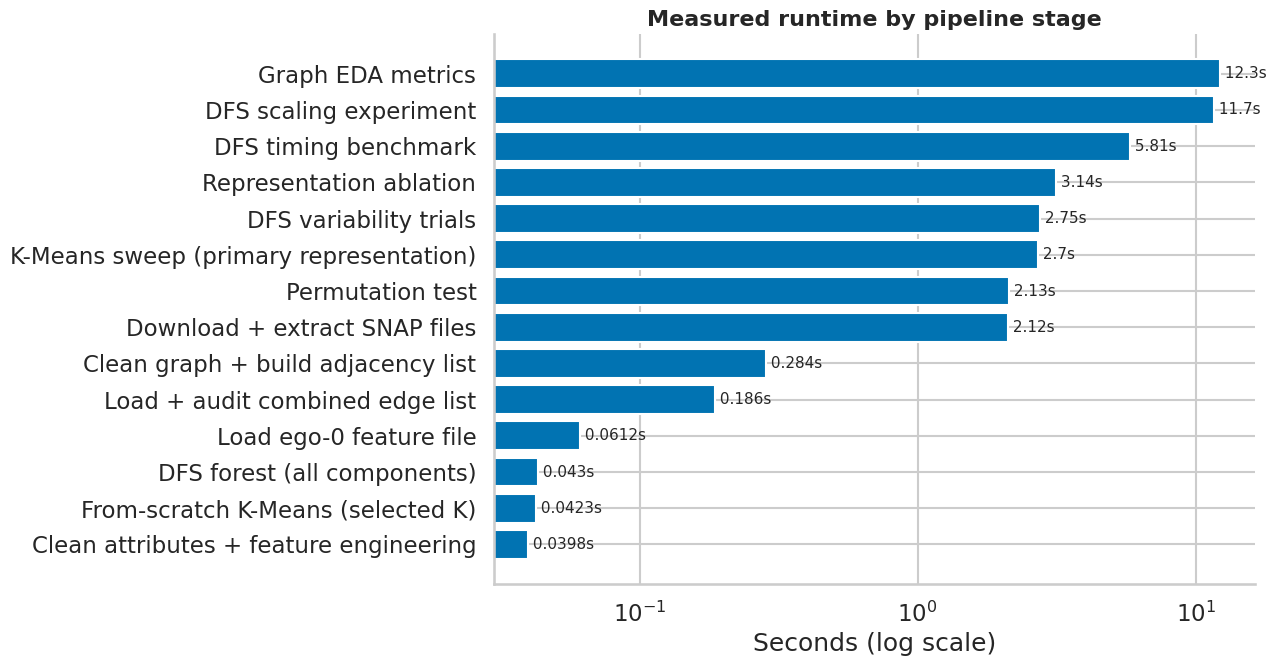

In [19]:
runtime_df = pd.DataFrame(TIMINGS).groupby("stage", sort=False).agg(seconds=("seconds", "sum"), scope=("scope", "first")).reset_index()
runtime_df["share_percent"] = 100 * runtime_df.seconds / runtime_df.seconds.sum()
display(runtime_df.round(4)); save_table(runtime_df, "runtime_by_stage")
fig, ax = plt.subplots(figsize=(13, 7)); rd = runtime_df.sort_values("seconds")
ax.barh(rd.stage, rd.seconds, color=PAL[0]); ax.set_xscale("log"); ax.set(title="Measured runtime by pipeline stage", xlabel="Seconds (log scale)")
for y, s in enumerate(rd.seconds): ax.text(s, y, f" {s:.3g}s", va="center", fontsize=11)
fig.tight_layout(); save_fig(fig, "fig13_runtime_by_stage", "Wall-clock time of each pipeline stage (log scale).")
R["runtime"] = {"stages": [{"stage": r.stage, "seconds": float(r.seconds), "scope": r.scope} for r in runtime_df.itertuples()]}


## 11. Consolidated results (accuracy and quality scores)
The summary table is what the report and poster quote. "Accuracy" is always qualified: *verification accuracy* for DFS and *matched clustering accuracy* (with baselines) for K-Means.


In [20]:
d_, k_, e_ = R["dfs"], R["kmeans"], R["external"]["first"]; p_ = R["external"]["perm"]
summary_df = pd.DataFrame([
    ("DFS", "Verification accuracy (checks passed)", f"{d_['verification_accuracy_pct']:.1f}% ({d_['checks_passed']}/{d_['checks_total']})", "Independent correctness checks"),
    ("DFS", "Edges satisfying DFS ancestor-descendant property", f"{d_['edge_property_pct']:.2f}%", "Nested discovery/finish intervals"),
    ("DFS", "Traversal coverage", f"{d_['coverage_pct']:.2f}% of {R['graph']['nodes']:,} nodes", f"{d_['roots']} DFS root(s)"),
    ("DFS", "Runtime (own implementation, mean +/- std)", f"{d_['own_mean_s']*1e3:.2f} +/- {d_['own_std_s']*1e3:.2f} ms", f"{d_['repeats']} repeats"),
    ("DFS", "Scaling fit (time vs V+E)", f"R^2 = {d_['scaling_r2']:.3f}", "Empirical O(V+E)"),
    ("K-Means", f"Selected K / representation", f"K = {k_['best_k']} / {k_['representation']}", CFG["K_SELECTION_RULE"]),
    ("K-Means", "Silhouette", f"{k_['silhouette']:.3f} ({k_['silhouette_label']})", "Internal"),
    ("K-Means", "Davies-Bouldin / Calinski-Harabasz", f"{k_['davies_bouldin']:.3f} / {k_['calinski_harabasz']:.1f}", "Internal"),
    ("K-Means", "Stability (pairwise ARI over seeds)", f"{k_['stability_ari']:.3f}", "1 = identical partitions"),
    ("K-Means", "Matched clustering accuracy vs circles", f"{e_['matched_accuracy']*100:.1f}% (majority baseline {e_['majority_baseline']*100:.1f}%, permuted mean {p_['matched_accuracy']['permuted_mean']*100:.1f}%)", f"n = {e_['n_eval']} labelled nodes"),
    ("K-Means", "ARI / NMI vs circles", f"{e_['ari']:.3f} / {e_['nmi']:.3f}", f"permutation p = {p_['ari']['p_value']:.3f} / {p_['nmi']['p_value']:.3f}"),
    ("K-Means", "Fit time (selected K)", f"{k_['fit_time_s']*1e3:.1f} ms", f"n_init = {k_['n_init']}"),
], columns=["algorithm", "metric", "value", "note"])
display(summary_df); save_table(summary_df, "results_summary")


,algorithm,metric,value,note
0,DFS,Verification accuracy (checks passed),100.0% (8/8),Independent correctness checks
1,DFS,Edges satisfying DFS ancestor-descendant property,100.00%,Nested discovery/finish intervals
2,DFS,Traversal coverage,"100.00% of 4,039 nodes",1 DFS root(s)
3,DFS,"Runtime (own implementation, mean +/- std)",36.13 +/- 7.93 ms,30 repeats
4,DFS,Scaling fit (time vs V+E),R^2 = 0.899,Empirical O(V+E)
5,K-Means,Selected K / representation,K = 2 / pca_binary,max silhouette among K with smallest cluster >...
6,K-Means,Silhouette,0.173 (no substantial structure),Internal
7,K-Means,Davies-Bouldin / Calinski-Harabasz,2.712 / 43.3,Internal
8,K-Means,Stability (pairwise ARI over seeds),0.876,1 = identical partitions
9,K-Means,Matched clustering accuracy vs circles,"31.5% (majority baseline 43.0%, permuted mean ...",n = 286 labelled nodes


## 12. Export: results file, poster text, formal report and ZIP
The next three cells (a) save the machine-readable results and the poster text, (b) build the **formal report (.docx)** from the numbers computed above, and (c) bundle everything into one ZIP. Re-running them after changing `CFG` regenerates all documents consistently.


Automatic interpretation sentences are generated from the numbers (and only state what the numbers support). They feed the poster text and the report.


In [21]:
# ======================================================================================
# Automatic, data-driven interpretation (used by poster text and report). No claim is
# written unless the corresponding number supports it.
# ======================================================================================
def band_stability(s):
    return "highly stable" if s >= 0.8 else ("moderately stable" if s >= 0.5 else "unstable")

def interpretations(R, sweep=None):
    g, d, k = R["graph"], R["dfs"], R["kmeans"]
    e, p = R["external"]["first"], R["external"]["perm"]
    out = {}
    full = d["coverage_pct"] >= 99.999 and d["checks_passed"] == d["checks_total"] and d["edge_property_pct"] >= 99.999
    out["rq1"] = ((f"Yes. The DFS forest visited {d['coverage_pct']:.2f}% of the {g['nodes']:,} nodes using {d['roots']} root(s), which equals the number of connected components found independently by NetworkX, "
                   f"and it passed all {d['checks_total']} verification checks; {d['edge_property_pct']:.2f}% of the {g['edges']:,} edges joined an ancestor and a descendant, as the theory requires for undirected graphs.")
                  if full else
                  (f"Partly. Coverage was {d['coverage_pct']:.2f}% and {d['checks_passed']}/{d['checks_total']} checks passed ({d['edge_property_pct']:.2f}% of edges satisfied the DFS property); "
                   "inspect the failed checks in the verification table before reporting."))
    r2 = d["scaling_r2"]
    out["rq2"] = (f"A straight-line fit of runtime against V + E on random sub-networks gave R\u00b2 = {r2:.3f} (slope {d['scaling_slope_us_per_unit']:.3f} \u00b5s per unit). "
                  + ("This is consistent with the theoretical O(V + E) behaviour." if r2 >= 0.95 else
                     "This is broadly consistent with O(V + E), but timing noise at millisecond scale reduces the fit." if r2 >= 0.8 else
                     "The fit is weak: at millisecond scale, timer resolution, memory effects and random sub-graph shape dominate, so the data neither confirm nor contradict O(V + E)."))
    out["dfs_shape"] = (f"The DFS tree has height {d['tree_height']:,} and mean node depth {d['mean_depth']:.1f}, with {d['back_edges']:,} back edges ({100*d['back_edges']/g['edges']:.1f}% of all edges) "
                        f"that close cycles. Over {CFG['DFS_VARIABILITY_TRIALS']} trials with random roots and neighbour orders the tree height ranged from {d['var_height_min']:,} to {d['var_height_max']:,}; "
                        "the DFS tree is therefore not unique, although coverage and correctness are unaffected.")
    sil = k["silhouette"]
    out["km_internal"] = (f"The pre-declared rule selected K = {k['best_k']} (silhouette {sil:.3f}, {k['silhouette_label']} on the Kaufman\u2013Rousseeuw scale; Davies\u2013Bouldin {k['davies_bouldin']:.3f}; "
                          f"Calinski\u2013Harabasz {k['calinski_harabasz']:.1f}). Other criteria preferred: " + ", ".join(f"{c} \u2192 K={v}" for c, v in k["criteria"].items()) + ". "
                          f"Seed stability (mean pairwise ARI) at the selected K was {k['stability_ari']:.3f} ({band_stability(k['stability_ari'])}).")
    gain = (e["matched_accuracy"] - e["majority_baseline"]) * 100
    sig = p["ari"]["p_value"] < 0.05
    if sweep is not None:
        abl = {r["representation"]: r for r in R["ablation"]["rows"]}; kk = k["best_k"]
        best_rep = max(abl, key=lambda r_: (abl[r_][f"ext_ari_at_K={kk}"] or -1)); prim = k["representation"]
        out["rq3"] = (f"Across K = {int(sweep.k.min())}\u2013{int(sweep.k.max())} the silhouette ranged from {sweep.silhouette.min():.3f} to {sweep.silhouette.max():.3f}, seed stability from {sweep.stability_ari.min():.2f} to {sweep.stability_ari.max():.2f}, "
                      f"and the fit time of one K-Means model (n_init = {k['n_init']}) from {sweep.fit_time_s.min()*1e3:.0f} to {sweep.fit_time_s.max()*1e3:.0f} ms. " + out["km_internal"] + " "
                      f"At K = {kk} the representation with the highest ARI against the circles was '{best_rep}' (ARI {abl[best_rep][f'ext_ari_at_K={kk}']:.3f}) compared with {abl[prim][f'ext_ari_at_K={kk}']:.3f} for the pre-declared primary representation '{prim}'.")
    out["rq4"] = (f"Against first-listed circle labels ({e['n_eval']} labelled nodes, {e['n_reference_classes']} classes) the clusters reached ARI {e['ari']:.3f}, NMI {e['nmi']:.3f} and a matched clustering accuracy of "
                  f"{100*e['matched_accuracy']:.1f}% versus a majority-class baseline of {100*e['majority_baseline']:.1f}% ({gain:+.1f} percentage points) and a permutation mean of {100*p['matched_accuracy']['permuted_mean']:.1f}%. "
                  + (f"The agreement is statistically above chance (permutation p = {p['ari']['p_value']:.3f} for ARI) but " + ("small in absolute terms" if e["ari"] < 0.3 else "substantial") + "."
                     if sig else f"The agreement is not distinguishable from chance (permutation p = {p['ari']['p_value']:.3f} for ARI)."))
    out["km_conclusion"] = (f"K-Means on the cleaned profile attributes produced clusters with a silhouette of {sil:.2f} ({k['silhouette_label']}); "
                            + ("attribute clusters therefore give only a weak summary of the profiles and agree only modestly with the social circles."
                               if (sil <= 0.5 and e['ari'] < 0.3) else
                               "the clusters are reasonably separated and show meaningful agreement with the circles." if (sil > 0.5 and e['ari'] >= 0.3) else
                               "internal quality and agreement with circles point in different directions, so the clusters should be interpreted cautiously."))
    out["dfs_conclusion"] = (f"DFS traversed the whole combined network ({d['coverage_pct']:.2f}% coverage) in {d['own_mean_s']*1e3:.1f} ms on average (own implementation) and its output was verified by {d['checks_passed']}/{d['checks_total']} independent checks.")
    return out
if "sweep_df" in globals():
    INTERP = interpretations(R, sweep_df); [print("-", v, "\n") for v in INTERP.values()]


- Yes. The DFS forest visited 100.00% of the 4,039 nodes using 1 root(s), which equals the number of connected components found independently by NetworkX, and it passed all 8 verification checks; 100.00% of the 88,234 edges joined an ancestor and a descendant, as the theory requires for undirected graphs. 

- A straight-line fit of runtime against V + E on random sub-networks gave R² = 0.899 (slope 0.303 µs per unit). This is broadly consistent with O(V + E), but timing noise at millisecond scale reduces the fit. 

- The DFS tree has height 1,858 and mean node depth 1004.9, with 84,196 back edges (95.4% of all edges) that close cycles. Over 30 trials with random roots and neighbour orders the tree height ranged from 1,717 to 2,650; the DFS tree is therefore not unique, although coverage and correctness are unaffected. 

- The pre-declared rule selected K = 2 (silhouette 0.173, no substantial structure on the Kaufman–Rousseeuw scale; Davies–Bouldin 2.712; Calinski–Harabasz 43.3). Other 

In [22]:
# ---- Machine-readable results and configuration -------------------------------------------------------------------
R["runtime_total_seconds_so_far"] = time.perf_counter() - NOTEBOOK_START
R["config"] = {k: to_py(v) if not isinstance(v, (list, dict)) else v for k, v in CFG.items()}
R["project"] = PROJECT_INFO
with open(OUT_DIR / "results.json", "w", encoding="utf-8") as f: json.dump(R, f, indent=2, default=to_py)
with open(OUT_DIR / "experiment_configuration.json", "w", encoding="utf-8") as f: json.dump({"config": R["config"], "environment": R["env"]}, f, indent=2, default=to_py)
pd.DataFrame([{"figure": k, "caption": v, "file": f"figures/{k}.png"} for k, v in FIGS.items()]).to_csv(OUT_DIR / "figure_index.csv", index=False)
node_assign = pd.DataFrame({"node_id": node_ids, "cluster": LABELS}); node_assign.to_csv(TAB_DIR / "node_cluster_assignments.csv", index=False)

# ---- Poster content (Introduction, Objectives, Literature review, Methodology, Results, Conclusion, References) ----------
g, d, k, ee = R["graph"], R["dfs"], R["kmeans"], R["external"]["first"]
poster = f"""# POSTER CONTENT - {PROJECT_INFO['title']}
{PROJECT_INFO['university']} | {PROJECT_INFO['course']} | Group: {PROJECT_INFO['group_name']}
Members: {'; '.join(PROJECT_INFO['members'])}

## 1. Introduction
- Online social networks encode who is connected to whom (structure) and what users share (profile attributes). Two classic algorithms analyse these complementary views: **DFS** explores connectivity; **K-Means** groups similar profiles.
- Data: SNAP *Social Circles: Facebook* - {g['nodes']:,} users, {g['edges']:,} friendships; ego network {CFG['EGO_ID']} with {R['features_raw']['n_nodes']} users, {R['features_raw']['n_attributes']} anonymised binary attributes and {R['features_raw']['n_circles']} manually defined circles.

## 2. Research objectives
1. Clean, audit and profile the graph and attribute data (EDA, feature engineering).
2. Implement DFS from scratch; verify correctness; measure coverage, tree structure, runtime and O(V+E) scaling.
3. Implement K-Means from scratch; choose K with several criteria; check stability and runtime.
4. Evaluate clusters internally and against social circles with baselines (ARI, NMI, matched accuracy, permutation test).

## 3. Literature review (short)
- McAuley & Leskovec [1] introduced ego networks with profile features and circles; SNAP [2] hosts the data.
- Tarjan [3] and Cormen et al. [4]: DFS gives linear-time O(V+E) connectivity and cycle analysis.
- MacQueen [5], Lloyd [6], Arthur & Vassilvitskii [7], Jain [8]: K-Means minimises within-cluster variance; results depend on scaling, seeding and K.
- Validation: silhouette [9,10], Davies-Bouldin [11], Calinski-Harabasz [12], ARI [13], NMI [14], Hungarian matching [15].

## 4. Methodology (use fig00_methodology_pipeline.png)
- Track A: edge list -> audit ({R['graph_audit']['self_loops']} self-loops, {R['graph_audit']['duplicates']} duplicates) -> adjacency list -> EDA -> iterative DFS forest -> verification + timing.
- Track B: ego-0 files -> audit -> remove {R['features']['removed_const']} constant and {R['features']['removed_rare']} rare attributes ({R['features']['attributes_after']} kept) -> feature engineering -> representations (binary / standardised / PCA / engineered) -> K-Means K={k['k_range'][0]}..{k['k_range'][1]} -> internal + external evaluation.

## 5. Key results (figures in `figures/`)
- Graph: avg degree {g['avg_degree']:.1f}, avg clustering {g['avg_clustering']:.3f}, max k-core {g['max_core']}, {g['components']} component(s) (fig01).
- DFS: coverage {d['coverage_pct']:.2f}%, verification {d['checks_passed']}/{d['checks_total']}, edges satisfying DFS property {d['edge_property_pct']:.2f}%, time {d['own_mean_s']*1e3:.1f} +/- {d['own_std_s']*1e3:.1f} ms, scaling R2 {d['scaling_r2']:.3f} (fig02-fig04).
- K-Means: K={k['best_k']}, silhouette {k['silhouette']:.3f}, DBI {k['davies_bouldin']:.2f}, stability {k['stability_ari']:.2f}; vs circles ARI {ee['ari']:.3f}, NMI {ee['nmi']:.3f}, matched accuracy {100*ee['matched_accuracy']:.1f}% (majority baseline {100*ee['majority_baseline']:.1f}%) (fig07-fig12).
- Runtime per stage: fig13.

## 6. Conclusion
- {INTERP['dfs_conclusion']}
- {INTERP['km_conclusion']}
- Limitations: one ego network for K-Means; anonymised attributes; simplified circle labels; hardware-dependent timings.

## 7. References
[1] J. McAuley and J. Leskovec, "Learning to discover social circles in ego networks," NIPS, 2012.
[2] J. Leskovec and A. Krevl, "SNAP Datasets: Stanford large network dataset collection," http://snap.stanford.edu/data, 2014.
[3] R. Tarjan, "Depth-first search and linear graph algorithms," SIAM J. Comput., 1(2):146-160, 1972.
[4] T. H. Cormen et al., Introduction to Algorithms, 3rd ed., MIT Press, 2009.
[5] J. MacQueen, "Some methods for classification and analysis of multivariate observations," Proc. 5th Berkeley Symp., 1967.
[6] S. P. Lloyd, "Least squares quantization in PCM," IEEE Trans. Inf. Theory, 28(2):129-137, 1982.
[7] D. Arthur and S. Vassilvitskii, "k-means++: The advantages of careful seeding," SODA, 2007.
[8] A. K. Jain, "Data clustering: 50 years beyond K-means," Pattern Recognit. Lett., 31(8):651-666, 2010.
[9] P. J. Rousseeuw, "Silhouettes," J. Comput. Appl. Math., 20:53-65, 1987.
[10] L. Kaufman and P. J. Rousseeuw, Finding Groups in Data, Wiley, 1990.
[11] D. L. Davies and D. W. Bouldin, "A cluster separation measure," IEEE TPAMI, 1(2):224-227, 1979.
[12] T. Calinski and J. Harabasz, "A dendrite method for cluster analysis," Commun. Stat., 3(1):1-27, 1974.
[13] L. Hubert and P. Arabie, "Comparing partitions," J. Classification, 2(1):193-218, 1985.
[14] A. Strehl and J. Ghosh, "Cluster ensembles," JMLR, 3:583-617, 2002.
[15] H. W. Kuhn, "The Hungarian method for the assignment problem," Nav. Res. Logist. Q., 2:83-97, 1955.
"""
(OUT_DIR / "poster_content.md").write_text(poster, encoding="utf-8")
print("Saved results.json, experiment_configuration.json, figure_index.csv, poster_content.md and", len(TABLES), "tables")


Saved results.json, experiment_configuration.json, figure_index.csv, poster_content.md and 21 tables


## 13. Formal report (.docx) generator
`build_report()` writes a complete academic report (cover page, abstract, contents, introduction, literature review, objectives, dataset, methodology, results, discussion, limitations, conclusion, references, appendices). All numbers, tables and figures are taken from the run above. **Edit `PROJECT_INFO` in §3** (members, IDs, instructor, course code) and re-run this cell. If your instructor gives a specific format, copy the generated tables/figures into that template — all tables are also saved as CSV in `tables/`.


In [23]:
from docx import Document
from docx.shared import Pt, Cm, Inches, RGBColor
from docx.enum.text import WD_ALIGN_PARAGRAPH, WD_COLOR_INDEX, WD_BREAK
from docx.enum.table import WD_TABLE_ALIGNMENT
from docx.oxml.ns import qn
from docx.oxml import OxmlElement

PH_RE = re.compile(r"(\[(?:\u25CF|[A-Za-z][^\]]*)\])")        # [●] and [Some placeholder] get highlighted
BOLD_RE = re.compile(r"(\*\*.+?\*\*)")
FONT = "Times New Roman"

def _style_font(style, size, bold=None, color=RGBColor(0, 0, 0), italic=None):
    style.font.name = FONT; style.font.size = Pt(size); style.font.color.rgb = color
    if bold is not None: style.font.bold = bold
    if italic is not None: style.font.italic = italic
    rpr = style.element.get_or_add_rPr(); rf = rpr.find(qn("w:rFonts"))
    if rf is None: rf = OxmlElement("w:rFonts"); rpr.append(rf)
    for a in ("w:asciiTheme", "w:hAnsiTheme", "w:eastAsiaTheme", "w:cstheme"):
        if rf.get(qn(a)) is not None: del rf.attrib[qn(a)]
    for a in ("w:ascii", "w:hAnsi", "w:eastAsia", "w:cs"): rf.set(qn(a), FONT)

def add_rich(p, text, bold=False, italic=False, size=None):
    for chunk in BOLD_RE.split(text):
        if not chunk: continue
        b = bold
        if chunk.startswith("**") and chunk.endswith("**") and len(chunk) > 4: chunk, b = chunk[2:-2], True
        for part in PH_RE.split(chunk):
            if not part: continue
            r = p.add_run(part); r.bold = b; r.italic = italic
            if size: r.font.size = Pt(size)
            if PH_RE.fullmatch(part): r.font.highlight_color = WD_COLOR_INDEX.YELLOW

def shade(cell, hex_fill):
    tcPr = cell._tc.get_or_add_tcPr(); sh = OxmlElement("w:shd")
    sh.set(qn("w:val"), "clear"); sh.set(qn("w:color"), "auto"); sh.set(qn("w:fill"), hex_fill); tcPr.append(sh)

def add_field(run, instr):
    for t, txt in (("begin", None), (None, instr), ("end", None)):
        if t:
            el = OxmlElement("w:fldChar"); el.set(qn("w:fldCharType"), t)
        else:
            el = OxmlElement("w:instrText"); el.set(qn("xml:space"), "preserve"); el.text = txt
        run._r.append(el)

class Vals:
    """Value accessor: returns formatted numbers from R, or a highlighted [●] placeholder in template mode."""
    def __init__(self, R, template): self.R, self.template = R, template
    def __call__(self, path, fmt="{}", scale=1.0):
        if self.template: return "[\u25CF]"
        cur = self.R
        for p_ in path.split("."): cur = cur[int(p_)] if isinstance(cur, list) else cur[p_]
        return fmt.format(cur * scale if scale != 1.0 else cur)

def placeholder_df(columns, n=3): return pd.DataFrame([["[\u25CF]"] * len(columns) for _ in range(n)], columns=columns)

def _fmt_val(x, digits=4):
    if isinstance(x, (bool, np.bool_)): return "Pass" if x else "FAIL"
    if isinstance(x, (float, np.floating)):
        if pd.isna(x): return ""
        return f"{int(x):,}" if float(x).is_integer() and abs(x) >= 1000 else f"{x:.{digits}g}"
    if isinstance(x, (int, np.integer)): return f"{x:,}" if abs(x) >= 10000 else str(x)
    return x

def fmt_df(df, digits=4):
    return df.apply(lambda col: col.map(lambda x: _fmt_val(x, digits)))

def build_report(R, out_path, template=False, tables=None, fig_dir=None, figs=None, interp=None):
    tables = tables or {}; figs = figs or {}; fig_dir = Path(fig_dir) if fig_dir else FIG_DIR
    v = Vals(R, template); TPH = "[\u25CF]"
    P = PROJECT_INFO

    def body(doc, toc_entries, collect):
        cnt = {"t": 0, "f": 0}
        def H(text, level=1):
            collect.append((level, text)); return doc.add_heading(text, level=level)
        def para(text, align=WD_ALIGN_PARAGRAPH.JUSTIFY, italic=False, bold=False, size=None, after=None, keep=False):
            p = doc.add_paragraph(); p.alignment = align; add_rich(p, text, bold=bold, italic=italic, size=size)
            if after is not None: p.paragraph_format.space_after = Pt(after)
            if keep: p.paragraph_format.keep_with_next = True
            return p
        def bullets(items):
            for it in items:
                p = doc.add_paragraph(style="List Bullet"); p.alignment = WD_ALIGN_PARAGRAPH.JUSTIFY; add_rich(p, it)
        def table(df, caption, font=8.5, widths=None):
            cnt["t"] += 1
            cap = doc.add_paragraph(style="Caption"); add_rich(cap, f"Table {cnt['t']}: {caption}"); cap.paragraph_format.keep_with_next = True
            df = fmt_df(df) if not template else df
            t = doc.add_table(rows=1, cols=len(df.columns)); t.style = "Table Grid"; t.alignment = WD_TABLE_ALIGNMENT.CENTER
            for i, c in enumerate(df.columns):
                cell = t.rows[0].cells[i]; cell.text = ""; add_rich(cell.paragraphs[0], str(c), bold=True, size=font); shade(cell, "D9E2F3")
            trPr = t.rows[0]._tr.get_or_add_trPr(); h = OxmlElement("w:tblHeader"); h.set(qn("w:val"), "true"); trPr.append(h)
            for row in df.itertuples(index=False):
                cells = t.add_row().cells
                for i, val in enumerate(row):
                    cells[i].text = ""; add_rich(cells[i].paragraphs[0], str(val), size=font)
            if widths:
                for row in t.rows:
                    for i, w_ in enumerate(widths): row.cells[i].width = Cm(w_)
            doc.add_paragraph().paragraph_format.space_after = Pt(2)
        def figure(name, caption, width=6.2):
            cnt["f"] += 1; path = fig_dir / f"{name}.png"; p = doc.add_paragraph(); p.alignment = WD_ALIGN_PARAGRAPH.CENTER; p.paragraph_format.keep_with_next = True
            if (not template) and path.exists(): p.add_run().add_picture(str(path), width=Inches(width))
            else: add_rich(p, f"[\u25CF Figure placeholder: {name}.png is created by the notebook]", italic=True)
            cap = doc.add_paragraph(style="Caption"); cap.alignment = WD_ALIGN_PARAGRAPH.CENTER; add_rich(cap, f"Figure {cnt['f']}: {caption}")
        def tbl(name, cols=None, rename=None, rows=None, placeholder_cols=None):
            if template: return placeholder_df(placeholder_cols or list((rename or {}).values()) or cols or ["Value"])
            df = tables[name]; df = df[cols] if cols else df
            if rows: df = df.head(rows)
            return df.rename(columns=rename or {})
        I = (lambda key: TPH + " " + "(interpretation is generated automatically from the results of the run)") if template else (lambda key: interp[key])

        # ------------------------------------------------------------------ cover page
        for txt, sz, b in [(P["university"].upper(), 16, True), (P["department"], 13, False)]:
            para(txt, WD_ALIGN_PARAGRAPH.CENTER, bold=b, size=sz, after=4)
        for _ in range(2): doc.add_paragraph()
        para("PROJECT REPORT", WD_ALIGN_PARAGRAPH.CENTER, bold=True, size=14, after=14)
        para(P["title"], WD_ALIGN_PARAGRAPH.CENTER, bold=True, size=20, after=18)
        para(f"Course: {P['course']} ({P['course_code']})", WD_ALIGN_PARAGRAPH.CENTER, size=13, after=4)
        para("Dataset: Stanford SNAP Social Circles: Facebook (ego-Facebook)", WD_ALIGN_PARAGRAPH.CENTER, size=12, after=4)
        para("Algorithms: Depth-First Search (DFS) and K-Means clustering", WD_ALIGN_PARAGRAPH.CENTER, size=12, after=24)
        t = doc.add_table(rows=2, cols=2); t.alignment = WD_TABLE_ALIGNMENT.CENTER
        for cell, txt in zip(t.rows[0].cells, ["Submitted to", f"Submitted by (Group: {P['group_name']})"]):
            cell.text = ""; add_rich(cell.paragraphs[0], txt, bold=True, size=12)
        t.rows[1].cells[0].text = ""; add_rich(t.rows[1].cells[0].paragraphs[0], P["instructor"], size=12)
        t.rows[1].cells[1].text = ""
        for i, m in enumerate(P["members"]):
            pp = t.rows[1].cells[1].paragraphs[0] if i == 0 else t.rows[1].cells[1].add_paragraph(); add_rich(pp, m, size=12)
        doc.add_paragraph(); para(f"Date of submission: {P['submission_date']}", WD_ALIGN_PARAGRAPH.CENTER, size=12)
        if template:
            para("TEMPLATE VERSION: every highlighted [\u25CF] value and figure placeholder is filled automatically when the notebook's report cell is run on your data. "
                 "Do not type results by hand.", WD_ALIGN_PARAGRAPH.CENTER, italic=True, size=10)
        doc.add_page_break()

        # ------------------------------------------------------------------ abstract + contents
        p = doc.add_paragraph(); p.alignment = WD_ALIGN_PARAGRAPH.CENTER; add_rich(p, "Abstract", bold=True, size=14)
        para(f"This project studies the Stanford SNAP *Social Circles: Facebook* data with two classical algorithms. Depth-First Search (DFS) was implemented from scratch and applied to the combined friendship network "
             f"({v('graph.nodes','{:,}')} users, {v('graph.edges','{:,}')} edges) after a documented quality audit and exploratory analysis. It visited {v('dfs.coverage_pct','{:.2f}')}% of the nodes, passed "
             f"{v('dfs.checks_passed')} of {v('dfs.checks_total')} independent correctness checks and ran in {v('dfs.own_mean_s','{:.1f}',1e3)} ms on average. K-Means (Lloyd's algorithm with k-means++ seeding, also implemented from scratch and cross-checked with scikit-learn) "
             f"was applied to {v('features_raw.n_nodes')} user profiles of ego network {CFG['EGO_ID']} after removing {v('features.removed_const')} constant and {v('features.removed_rare')} rare attributes and engineering four candidate representations. "
             f"The selected model (K = {v('kmeans.best_k')}) obtained a silhouette of {v('kmeans.silhouette','{:.3f}')} and an adjusted Rand index of {v('external.first.ari','{:.3f}')} against the social circles, "
             f"with a matched clustering accuracy of {v('external.first.matched_accuracy','{:.1f}',100)}% against a majority baseline of {v('external.first.majority_baseline','{:.1f}',100)}%. "
             f"{I('km_conclusion')} All figures, tables and timings in this report were generated by one reproducible notebook.".replace("*Social Circles: Facebook*", "Social Circles: Facebook"))
        para("**Keywords:** social network analysis; ego network; depth-first search; K-Means; clustering validation; reproducibility.", after=10)
        p = doc.add_paragraph(); p.alignment = WD_ALIGN_PARAGRAPH.CENTER; add_rich(p, "Contents", bold=True, size=14)
        if toc_entries:
            for i, (lvl, txt) in enumerate(toc_entries):
                q = doc.add_paragraph(); q.paragraph_format.left_indent = Cm(0.6 * (lvl - 1)); q.paragraph_format.space_after = Pt(1)
                if i == 0:
                    r0 = q.add_run(); fc = OxmlElement("w:fldChar"); fc.set(qn("w:fldCharType"), "begin"); r0._r.append(fc)
                    r1 = q.add_run(); it = OxmlElement("w:instrText"); it.set(qn("xml:space"), "preserve"); it.text = ' TOC \\o "1-2" \\h \\z \\u '; r1._r.append(it)
                    r2 = q.add_run(); fs = OxmlElement("w:fldChar"); fs.set(qn("w:fldCharType"), "separate"); r2._r.append(fs)
                add_rich(q, txt, bold=(lvl == 1))
                if i == len(toc_entries) - 1:
                    r3 = q.add_run(); fe = OxmlElement("w:fldChar"); fe.set(qn("w:fldCharType"), "end"); r3._r.append(fe)
            para("(In Word: right-click the contents list and choose Update Field to add page numbers.)", italic=True, size=9, after=0)
        doc.add_page_break()

        # ------------------------------------------------------------------ 1 Introduction
        H("1. Introduction")
        H("1.1 Background and motivation", 2)
        para("Online social networks record two complementary kinds of information: **structure** (who is connected to whom) and **attributes** (what users report about themselves). Structural analysis answers questions about reachability, connectivity and cycles; attribute analysis answers questions about which users resemble one another. "
             "Both are building blocks of friend recommendation, community detection and the study of information flow [20].")
        para("This project applies one classical algorithm to each view of the same public dataset: **Depth-First Search (DFS)** to explore the friendship graph, and **K-Means** to cluster user profiles. The emphasis is not only on running the algorithms but on a defensible workflow: auditing and cleaning the data, engineering features, "
             "verifying that the implementations are correct, measuring runtime, and reporting accuracy-type scores together with baselines so that results are not over-interpreted.")
        H("1.2 Problem statement", 2)
        para("Given the SNAP Facebook ego-network data, (i) traverse the complete combined network with DFS and demonstrate that the traversal is correct, complete and efficient; and (ii) cluster the profile attributes of one ego network with K-Means, select the number of clusters objectively, and assess whether the resulting groups correspond to the manually defined social circles.")
        H("1.3 Scope and contributions", 2)
        bullets(["A documented data-quality audit, cleaning protocol, exploratory analysis and feature-engineering stage for both the graph and the attribute data.",
                 "From-scratch implementations of iterative DFS (with discovery/finishing times) and K-Means (Lloyd + k-means++), each validated against an independent reference.",
                 "A verification-based definition of \"accuracy\" for DFS and a baseline-controlled clustering accuracy for K-Means.",
                 "Per-stage runtime measurements, an empirical O(V+E) scaling experiment and a stability analysis of K-Means.",
                 "A fully reproducible notebook that generates every table and figure of this report and of the accompanying poster."])
        para("DFS and K-Means operate on different data (the whole graph versus one ego network's attribute matrix), so their runtimes are reported separately and are not presented as a head-to-head speed comparison.")

        # ------------------------------------------------------------------ 2 Literature
        H("2. Literature Review")
        H("2.1 Ego networks and social circles", 2)
        para("An ego network consists of a focal user (the ego), the ego's friends (alters) and the friendships among them. McAuley and Leskovec [1] collected ego networks from survey participants through a Facebook application, together with anonymised profile attributes and the friend lists (\"circles\") that participants created manually. "
             "Their work studied how circles can be discovered automatically by combining network structure with profile similarity. The resulting collection is distributed by the Stanford Network Analysis Project (SNAP) [2]. This report does not attempt to reproduce the circle-discovery model of [1]; it uses the same data to evaluate two classical algorithms transparently.")
        H("2.2 Depth-first search", 2)
        para("Depth-first search explores a branch of a graph as far as possible before backtracking. Tarjan [3] showed that DFS yields linear-time algorithms for connectivity, biconnected and strongly connected components, and Cormen et al. [4] formalise the discovery and finishing times used in this report. "
             "With an adjacency-list representation DFS runs in \u0398(V + E) time. In an undirected graph every non-tree edge is a back edge, so the [discovery, finish] intervals of any two adjacent nodes are nested (the parenthesis property); this property is used here as an independent correctness test. "
             "DFS underlies component discovery, cycle detection, articulation-point analysis and topological ordering, all of which are common in network analysis [20].")
        H("2.3 K-Means clustering", 2)
        para("K-Means partitions n observations into K clusters by minimising the within-cluster sum of squared distances (inertia). MacQueen [5] introduced the name and the sequential update; Lloyd's iterative assignment\u2013update procedure [6] is the version most widely used today. "
             "The result depends on initialisation; k-means++ seeding [7] spreads the initial centres and gives a provable approximation guarantee in expectation. Jain's review [8] highlights further practical issues: K must be specified, clusters are assumed roughly spherical, and the outcome is sensitive to feature scaling and to irrelevant features. "
             "For sparse binary profile data, Euclidean distance reduces to the square root of the Hamming distance and is dominated by frequently active attributes, which motivates comparing raw, standardised and PCA-reduced [19] representations.")
        H("2.4 Cluster validation", 2)
        para("Internal indices judge a partition without external labels. The silhouette coefficient [9] compares each point's cohesion with its separation from the nearest other cluster; Kaufman and Rousseeuw [10] suggest reading values above 0.70 as strong, 0.51\u20130.70 as reasonable, 0.26\u20130.50 as weak and \u2264 0.25 as no substantial structure. "
             "The Davies\u2013Bouldin index [11] (lower is better) and the Calinski\u2013Harabasz index [12] (higher is better) summarise cluster compactness and separation. External indices compare a partition with reference labels: the Adjusted Rand Index [13] corrects pair-counting agreement for chance, and Normalised Mutual Information [14] measures shared information. "
             "A clustering \"accuracy\" requires mapping clusters to classes; the optimal one-to-one mapping is found with the Hungarian algorithm [15]. Because accuracy is meaningless without context, it is reported here beside the majority-class baseline and a label-permutation baseline. "
             "Cluster stability across random restarts is a further practical check of reliability.")
        H("2.5 Positioning of this work", 2)
        para("Prior work on this dataset concentrates on detecting circles with models that use structure and attributes jointly [1]. This project instead isolates two classical building blocks, DFS for structure and K-Means for attributes, and evaluates them under a reproducible protocol with verification, baselines and runtime accounting. "
             "Community detection with Louvain modularity optimisation [16] is used only as a reference to ask whether attribute clusters mirror network structure.")

        # ------------------------------------------------------------------ 3 Objectives
        H("3. Research Objectives and Questions")
        H("3.1 Objectives", 2)
        bullets(["**O1.** Load, audit, clean and profile the combined graph and the ego-network-0 attribute data.",
                 "**O2.** Implement DFS and apply it to the whole combined network; verify correctness; measure coverage, tree structure, runtime and scaling.",
                 "**O3.** Implement K-Means, engineer features and compare representations; select K with several criteria and test stability.",
                 "**O4.** Evaluate the clusters internally and externally against social circles with proper baselines.",
                 "**O5.** Produce reproducible tables and figures for this report and the poster."])
        H("3.2 Research questions", 2)
        bullets(["**RQ1.** Does DFS, run per connected component, visit every node, and does the DFS forest satisfy the formal DFS properties?",
                 "**RQ2.** Does DFS runtime grow linearly with V + E on real sub-networks of increasing size?",
                 "**RQ3.** How do K-Means quality, stability and runtime change with K and with the feature representation?",
                 "**RQ4.** Do attribute-based clusters agree with the social circles beyond what chance would give?"])

        # ------------------------------------------------------------------ 4 Dataset
        H("4. Dataset Description")
        para(f"The SNAP *Social Circles: Facebook* collection contains ten anonymised ego networks. Two files are used: `facebook_combined.txt.gz`, an undirected edge list that merges all ego networks (used by DFS), and `facebook.tar.gz`, which provides for each ego the files `.edges`, `.feat`, `.featnames`, `.egofeat` and `.circles` (used by K-Means). "
             f"The published SNAP statistics are 4,039 nodes and 88,234 edges [2]. Profile attributes are binary and anonymised: the data reveal whether two users share an attribute value, not what the value is. Ego network {CFG['EGO_ID']} is used for clustering.".replace("*", "").replace("`", ""))
        table(pd.DataFrame([("facebook_combined.txt.gz", "Edge list of all ego networks combined", "DFS, graph EDA"),
                            (f"{CFG['EGO_ID']}.feat / .featnames", "Binary attribute matrix of alters and anonymised attribute names", "K-Means, feature EDA"),
                            (f"{CFG['EGO_ID']}.edges", "Friendships among the alters of ego network", "Structural features, Louvain reference"),
                            (f"{CFG['EGO_ID']}.circles", "Manually defined, possibly overlapping friend lists", "External evaluation only")],
                           columns=["File", "Content", "Use in this project"]), "Files used in the experiments.", font=9)
        para("**Ethical note.** The data are publicly released and anonymised. No attempt was made to re-identify users or to infer the meaning of anonymised attributes.")

        # ------------------------------------------------------------------ 5 Methodology
        H("5. Methodology")
        H("5.1 Overview", 2)
        figure("fig00_methodology_pipeline", "Methodology overview: two parallel tracks from raw SNAP files to the report and poster.", 6.4)
        H("5.2 Data audit and cleaning: graph", 2)
        para("Each raw edge record was parsed and checked for malformed lines, self-loops, duplicate and reversed-duplicate edges and node-ID continuity. Because the graph is undirected, (u, v) and (v, u) denote one friendship. Self-loops were removed and duplicates collapsed. "
             "The cleaned graph was stored as sorted adjacency lists (making DFS deterministic) and as a NetworkX graph (for EDA). Symmetry of the adjacency list and the identity sum of degrees = 2|E| were asserted. The resulting statistics were compared with the values published by SNAP as a sanity check.")
        H("5.3 Exploratory analysis: graph", 2)
        para("Degree distribution and its complementary cumulative distribution, local clustering coefficient against degree, k-core decomposition, connected components, transitivity, assortativity and a sampled lower bound of the diameter (breadth-first searches from a random sample of sources) were computed.")
        H("5.4 DFS implementation and verification", 2)
        para("DFS was implemented iteratively with an explicit stack of neighbour iterators, so that deep traversals cannot exceed Python's recursion limit. The procedure is repeated from every unvisited node, which produces a DFS forest that covers all connected components. For every node it records the parent, depth, discovery time d(u) and finishing time f(u). "
             "Time complexity is \u0398(V + E) and extra space is \u0398(V). The implementation was first unit-tested on a five-node graph with a hand-derived DFS order.")
        para("**Verification accuracy.** DFS is not a predictive model, so classification accuracy does not apply. Instead eight independent checks were defined (no duplicate visits, visited set equals node set, number of roots equals the number of NetworkX connected components, every tree edge exists in the graph, tree edges = V \u2212 components, "
             "reachable set equals NetworkX's DFS reachable set, every edge joins an ancestor and descendant, and discovery/finish times are consistent). The verification accuracy is the share of checks passed; additionally the percentage of graph edges whose endpoints have nested [d, f] intervals is reported.")
        para(f"**Timing and scaling.** The DFS was timed over {CFG['DFS_REPEATS']} repeated runs with the garbage collector paused (mean, standard deviation, minimum, median) and compared with NetworkX's DFS as a reference. "
             f"Scaling was assessed on random induced sub-networks containing 10%\u2013100% of the nodes ({CFG['SCALING_REPEATS']} repetitions each, best of three timings per sample) with a linear regression of runtime on V + E. "
             f"Sensitivity of the DFS tree to the root and to neighbour order was examined over {CFG['DFS_VARIABILITY_TRIALS']} randomised trials.")
        H("5.5 Data audit and cleaning: attributes", 2)
        para(f"The attribute file of ego network {CFG['EGO_ID']} was checked for missing values, non-binary values, duplicate node IDs, identical attribute vectors, nodes with no active attributes, constant and rare attributes, and for the alignment of its nodes with the ego edge file, the combined graph and the circle files. "
             f"Constant attributes (all 0 or all 1) and rare attributes (fewer than {CFG['MIN_NODES_PER_FEATURE']} nodes) were removed. Duplicate attribute vectors and nodes without active attributes were kept because they are legitimate users.")
        H("5.6 Feature extraction and engineering", 2)
        para("Attribute categories were extracted from the anonymised feature names (the text before \"anonymized feature\"). Engineered features comprise the number of active attributes per node, activation counts per category and four structural features (degree within the ego network, degree in the combined graph, local clustering coefficient and k-core number). "
             f"Four representations were compared: (1) the cleaned binary matrix; (2) the standardised binary matrix; (3) a PCA projection retaining {CFG['PCA_VARIANCE']:.0%} of the variance; (4) the low-dimensional engineered feature vector, standardised. "
             f"The PCA representation (`{CFG['PRIMARY_REPRESENTATION']}`) was declared the primary representation before any external label was examined, to avoid tuning to the circles.".replace("`", ""))
        H("5.7 K-Means implementation, model selection and evaluation", 2)
        para(f"Lloyd's algorithm with k-means++ seeding, {CFG['N_INIT']} restarts and empty-cluster repair was implemented from scratch and validated on synthetic blobs with known structure (ARI > 0.95) and against scikit-learn's KMeans on the real data. "
             f"K was varied from {CFG['K_MIN']} to {CFG['K_MAX']}. The pre-declared selection rule was: {CFG['K_SELECTION_RULE']}. Elbow (maximum distance from the chord of the normalised inertia curve), Davies\u2013Bouldin, Calinski\u2013Harabasz and stability preferences are reported for comparison.")
        para(f"Internal quality: inertia, silhouette, Davies\u2013Bouldin and Calinski\u2013Harabasz. Stability: mean pairwise ARI between {CFG['STABILITY_SEEDS']} single-start runs with different seeds. External agreement: reference labels were derived from the circles (the first-listed circle of each node; the largest circle containing the node is used as an alternative). "
             "Metrics are ARI, NMI, homogeneity, completeness, V-measure, purity and Hungarian-matched clustering accuracy. Chance levels are estimated by "
             f"{CFG['PERMUTATION_TESTS']} random permutations of the reference labels, giving permutation p-values. Finally, Louvain communities [16] of the ego network were compared with the clusters to check whether attribute clusters reflect network structure.")
        H("5.8 Experimental environment", 2)
        env_df = pd.DataFrame([("Python", v("env.python")), ("NetworkX", v("env.networkx")), ("scikit-learn", v("env.scikit_learn")), ("NumPy / pandas", f"{v('env.numpy')} / {v('env.pandas')}"),
                               ("Platform", v("env.platform")), ("CPU cores", v("env.cpu_count")), ("Random seed", v("env.seed")), ("Run started", v("env.run_started"))], columns=["Item", "Value"])
        table(env_df, "Software and hardware environment of the reported run.", font=9); env_tno = cnt["t"]

        # ------------------------------------------------------------------ 6 Results
        H("6. Results")
        H("6.1 Graph quality audit and profile", 2)
        table(tbl("graph_quality_audit", rename={"check": "Check", "value": "Value", "decision": "Decision"}, placeholder_cols=["Check", "Value", "Decision"]), "Quality audit of the raw combined edge list and the cleaning decisions.", widths=[5.5, 3.0, 7.5])
        gp = pd.DataFrame([("Nodes / edges", f"{v('graph.nodes','{:,}')} / {v('graph.edges','{:,}')}"), ("Density", v("graph.density", "{:.5f}")), ("Average / median / max degree", f"{v('graph.avg_degree','{:.2f}')} / {v('graph.median_degree','{:.0f}')} / {v('graph.max_degree')}"),
                           ("Average local clustering / transitivity", f"{v('graph.avg_clustering','{:.4f}')} / {v('graph.transitivity','{:.4f}')}"), ("Triangles", v("graph.triangles", "{:,}")), ("Maximum k-core", v("graph.max_core")),
                           ("Connected components (largest)", f"{v('graph.components')} ({v('graph.largest_component','{:,}')} nodes)"), ("Diameter lower bound / mean path length (sampled)", f"{v('graph.diameter_lower_bound')} / {v('graph.avg_path_length_est','{:.2f}')}"),
                           ("Degree assortativity", v("graph.assortativity", "{:.4f}"))], columns=["Metric", "Value"])
        table(gp, "Profile of the cleaned combined network.", font=9)
        table(tbl("graph_vs_snap_reference", rename={"statistic": "Statistic", "this_run": "This run", "snap_published": "SNAP published", "agrees": "Agrees"}, placeholder_cols=["Statistic", "This run", "SNAP published", "Agrees"]), "Comparison of the recomputed statistics with those published on the SNAP dataset page [2].", font=9)
        figure("fig01_graph_eda", "Exploratory analysis of the combined network.")
        H("6.2 DFS results", 2)
        table(tbl("dfs_verification_checks", rename={"check": "Verification check", "passed": "Result"}, placeholder_cols=["Verification check", "Result"]), "DFS correctness checks (basis of the verification accuracy).", widths=[12.0, 3.0], font=9)
        dd = pd.DataFrame([("Verification accuracy", f"{v('dfs.verification_accuracy_pct','{:.1f}')}% ({v('dfs.checks_passed')}/{v('dfs.checks_total')} checks)"), ("Edges satisfying the ancestor\u2013descendant property", f"{v('dfs.edge_property_pct','{:.2f}')}%"),
                           ("Traversal coverage", f"{v('dfs.coverage_pct','{:.2f}')}%"), ("DFS roots / connected components", f"{v('dfs.roots')} / {v('graph.components')}"), ("Tree edges / back edges", f"{v('dfs.tree_edges','{:,}')} / {v('dfs.back_edges','{:,}')}"),
                           ("Tree height / mean depth", f"{v('dfs.tree_height','{:,}')} / {v('dfs.mean_depth','{:.1f}')}"), ("Runtime, own DFS (mean \u00b1 std, ms)", f"{v('dfs.own_mean_s','{:.2f}',1e3)} \u00b1 {v('dfs.own_std_s','{:.2f}',1e3)}"),
                           ("Runtime, NetworkX reference (mean \u00b1 std, ms)", f"{v('dfs.nx_mean_s','{:.2f}',1e3)} \u00b1 {v('dfs.nx_std_s','{:.2f}',1e3)}"), ("Peak extra memory of one DFS run (MB)", v("dfs.peak_memory_mb", "{:.2f}")),
                           ("Scaling fit: R\u00b2 / slope (\u00b5s per V+E unit)", f"{v('dfs.scaling_r2','{:.3f}')} / {v('dfs.scaling_slope_us_per_unit','{:.3f}')}"),
                           (f"Tree height over {CFG['DFS_VARIABILITY_TRIALS']} random trials (min\u2013max)", f"{v('dfs.var_height_min','{:,}')} \u2013 {v('dfs.var_height_max','{:,}')}")], columns=["Measure", "Value"])
        table(dd, "DFS results on the combined network.", font=9)
        para(I("dfs_shape"))
        figure("fig02_dfs_analysis", "DFS behaviour: depth profile, depth distribution and sensitivity of tree height."); figure("fig03_dfs_scaling", "Empirical scaling of DFS runtime with V + E.", 4.8)
        figure("fig04_dfs_tree_ego0", "DFS tree drawn on ego network 0 for illustration.", 5.0)
        H("6.3 Attribute data preparation", 2)
        table(tbl("feature_quality_audit", rename={"check": "Check", "value": "Value"}, placeholder_cols=["Check", "Value"]), f"Quality audit of the ego-network {CFG['EGO_ID']} attribute matrix.", widths=[11.0, 3.0], font=9)
        table(tbl("feature_cleaning_summary", rename={"item": "Item", "value": "Value"}, placeholder_cols=["Item", "Value"]), "Effect of cleaning and feature engineering.", widths=[11.0, 3.0], font=9)
        figure("fig05_feature_eda", "Exploratory analysis of the attribute data."); figure("fig06_feature_engineering", "PCA variance retention and correlations of the engineered features.")
        H("6.4 K-Means model selection", 2)
        table(tbl("kmeans_sweep_primary", cols=["k", "inertia", "silhouette", "davies_bouldin", "calinski_harabasz", "stability_ari", "min_cluster", "fit_time_s"],
                  rename={"k": "K", "inertia": "Inertia", "silhouette": "Silhouette", "davies_bouldin": "DBI", "calinski_harabasz": "CH", "stability_ari": "Stability (ARI)", "min_cluster": "Min size", "fit_time_s": "Fit (s)"},
                  placeholder_cols=["K", "Inertia", "Silhouette", "DBI", "CH", "Stability (ARI)", "Min size", "Fit (s)"]), f"K-Means results for the primary representation.", font=8)
        table(tbl("kmeans_k_criteria", rename={"criterion": "Criterion", "preferred_k": "Preferred K"}, placeholder_cols=["Criterion", "Preferred K"]), "Number of clusters preferred by each criterion.", widths=[6.0, 3.0], font=9)
        para(I("km_internal")); figure("fig07_kmeans_model_selection", "Model-selection curves over K.")
        H("6.5 Selected clustering", 2)
        figure("fig08_kmeans_pca_projection", "PCA projection of the profiles coloured by cluster and by circle."); figure("fig09_kmeans_silhouette_sizes", "Silhouette plot and cluster sizes.", 5.6)
        table(tbl("kmeans_cluster_top_attributes", cols=["cluster", "size", "attribute", "prevalence_in_cluster", "prevalence_elsewhere"], rename={"cluster": "Cluster", "size": "Size", "attribute": "Top distinguishing attribute", "prevalence_in_cluster": "In cluster", "prevalence_elsewhere": "Elsewhere"},
                  placeholder_cols=["Cluster", "Size", "Top distinguishing attribute", "In cluster", "Elsewhere"], rows=18), "Attributes that most distinguish each cluster (anonymised names; category#index).", font=8)
        figure("fig10_cluster_profiles", "Attribute-category profile of each cluster.", 5.4)
        H("6.6 Agreement with social circles", 2)
        table(tbl("kmeans_external_evaluation", cols=["labelling_scheme", "n_eval", "n_reference_classes", "ari", "nmi", "purity", "matched_accuracy", "majority_baseline"],
                  rename={"labelling_scheme": "Labels", "n_eval": "Nodes", "n_reference_classes": "Classes", "ari": "ARI", "nmi": "NMI", "purity": "Purity", "matched_accuracy": "Matched acc.", "majority_baseline": "Majority base."},
                  placeholder_cols=["Labels", "Nodes", "Classes", "ARI", "NMI", "Purity", "Matched acc.", "Majority base."]), "External evaluation against circle-derived labels (accuracy-type scores shown with the majority baseline).", font=8.5)
        table(tbl("kmeans_permutation_test", rename={"metric": "Metric", "observed": "Observed", "permuted_mean": "Permuted mean", "permuted_95th_pct": "Permuted 95th pct.", "p_value": "p-value"}, placeholder_cols=["Metric", "Observed", "Permuted mean", "Permuted 95th pct.", "p-value"]), f"Permutation test ({CFG['PERMUTATION_TESTS']} shuffles of the reference labels).", font=9)
        figure("fig11_clusters_vs_circles_network", "Clusters versus circles and ego network coloured by cluster.")
        lv = (R["external"].get("louvain") if not template else None)
        if template or lv:
            para(f"As a structural reference, Louvain found {v('external.louvain.n_communities')} communities in the ego network; their agreement with the K-Means clusters was NMI {v('external.louvain.nmi_vs_kmeans','{:.3f}')} (ARI {v('external.louvain.ari_vs_kmeans','{:.3f}')}), "
                 f"and their agreement with the circles was NMI {v('external.louvain.nmi_vs_circles','{:.3f}')}, which indicates how much of the circle structure is recoverable from the network alone.")
        H("6.7 Representation ablation and implementation cross-check", 2)
        table(tbl("kmeans_representation_ablation", cols=["representation", "dims", "best_k_by_silhouette", "silhouette", "davies_bouldin", f"ext_ari_at_K={R['kmeans']['best_k'] if not template else 0}", f"ext_nmi_at_K={R['kmeans']['best_k'] if not template else 0}"] if not template else None,
                  rename={"representation": "Representation", "dims": "Dims", "best_k_by_silhouette": "Best K", "silhouette": "Silhouette", "davies_bouldin": "DBI", **({f"ext_ari_at_K={R['kmeans']['best_k']}": "ARI at selected K", f"ext_nmi_at_K={R['kmeans']['best_k']}": "NMI at selected K"} if not template else {})},
                  placeholder_cols=["Representation", "Dims", "Best K", "Silhouette", "DBI", "ARI at selected K", "NMI at selected K"]), "Effect of the feature representation. Silhouette values from different spaces are not directly comparable; ARI/NMI are.", font=8.5)
        table(tbl("kmeans_scratch_vs_sklearn", rename={"implementation": "Implementation", "inertia": "Inertia", "iterations": "Iterations", "time_s": "Time (s)"}, placeholder_cols=["Implementation", "Inertia", "Iterations", "Time (s)"]), "From-scratch K-Means versus scikit-learn at the selected K.", font=9)
        para(f"The two implementations differ in final inertia by {v('kmeans.inertia_gap_pct','{:.3f}')}% and their partitions agree with an ARI of {v('kmeans.partition_ari','{:.3f}')}, which supports the correctness of the from-scratch code.")
        figure("fig12_convergence_ablation", "Convergence of the from-scratch K-Means and representation ablation.")
        H("6.8 Runtime by stage", 2)
        table(tbl("runtime_by_stage", cols=["stage", "seconds", "share_percent"], rename={"stage": "Stage", "seconds": "Seconds", "share_percent": "Share (%)"}, placeholder_cols=["Stage", "Seconds", "Share (%)"]), "Measured wall-clock time per pipeline stage.", widths=[9.0, 3.0, 3.0], font=9)
        figure("fig13_runtime_by_stage", "Runtime by pipeline stage (log scale).", 5.4)
        para(f"The complete notebook ran in {v('runtime_total_seconds_so_far','{:.1f}')} seconds up to the export step on the environment of Table {env_tno}. "
             "DFS and K-Means process different data, so the table documents per-stage cost rather than a comparison of the algorithms.")
        H("6.9 Summary of scores", 2)
        table(tbl("results_summary", rename={"algorithm": "Algorithm", "metric": "Metric", "value": "Value", "note": "Note"}, placeholder_cols=["Algorithm", "Metric", "Value", "Note"]), "Summary of accuracy and quality scores.", widths=[2.2, 5.2, 5.6, 3.8], font=8.5)

        # ------------------------------------------------------------------ 7 Discussion
        H("7. Discussion")
        para("**RQ1 (DFS correctness and coverage).** " + I("rq1"))
        para("**RQ2 (scaling).** " + I("rq2"))
        para("**RQ3 (K-Means quality, stability, representation).** " + I("rq3") + " The primary representation was fixed before any external label was examined and was not changed afterwards, to avoid selecting features by their agreement with the circles.")
        para("**RQ4 (agreement with circles).** " + I("rq4"))
        para("**Interpretation.** Structure and attributes capture different aspects of a social neighbourhood. DFS reveals connectivity and cycles but not communities; K-Means summarises similar profiles but has no access to who is connected to whom. "
             "The comparison with Louvain communities and with the circles (Section 6.6) shows how far each signal alone recovers the circles; McAuley and Leskovec [1] argue that both signals matter.")
        # ------------------------------------------------------------------ 8 Limitations
        H("8. Limitations and Threats to Validity")
        bullets(["K-Means was applied to a single ego network (n \u2248 350 users); conclusions may not transfer to the other ego networks or to larger populations.",
                 "Attributes are anonymised, binary and sparse; Euclidean K-Means assumes compact, roughly spherical clusters, which profile data may not satisfy.",
                 "Circles overlap and are incomplete. Reducing each node to one label (first-listed or largest circle) discards information, so ARI, NMI and matched accuracy are lower bounds on possible agreement and depend on the labelling rule.",
                 "Silhouette values from different feature spaces are not comparable; the choice of PCA variance (0.90) and of the rarity threshold are design decisions examined only through the ablation.",
                 "DFS trees are not unique; the reported tree height depends on root and neighbour order (quantified in Section 6.2).",
                 "Runtimes are measured in pure Python on shared cloud hardware; they vary between runs and machines and are not a benchmark of the algorithms. DFS and K-Means timings are not comparable with each other.",
                 "The permutation test assumes exchangeability of labels and ignores network dependence between users."])
        # ------------------------------------------------------------------ 9 Conclusion
        H("9. Conclusion and Future Work")
        para(I("dfs_conclusion")); para(I("km_conclusion"))
        para("Taken together, the study shows how a classical traversal algorithm and a classical clustering algorithm can be evaluated rigorously on a real social network: with documented cleaning, verified implementations, baseline-controlled accuracy and transparent timing.")
        para("**Future work:** (i) repeat the analysis on all ten ego networks; (ii) use similarity measures designed for binary data (Hamming, Jaccard) or K-Modes / K-Medoids; (iii) combine attributes and structure in a single model such as spectral clustering; (iv) compare DFS with breadth-first search and with an optimised (compiled) implementation; (v) evaluate overlapping-community methods against the circles.")
        # ------------------------------------------------------------------ References
        H("References")
        refs = ["J. McAuley and J. Leskovec, \"Learning to discover social circles in ego networks,\" in Advances in Neural Information Processing Systems (NIPS), 2012.",
                "J. Leskovec and A. Krevl, \"SNAP Datasets: Stanford large network dataset collection,\" 2014. [Online]. Available: http://snap.stanford.edu/data (Social Circles: Facebook, https://snap.stanford.edu/data/ego-Facebook.html).",
                "R. Tarjan, \"Depth-first search and linear graph algorithms,\" SIAM Journal on Computing, vol. 1, no. 2, pp. 146\u2013160, 1972.",
                "T. H. Cormen, C. E. Leiserson, R. L. Rivest and C. Stein, Introduction to Algorithms, 3rd ed. Cambridge, MA, USA: MIT Press, 2009.",
                "J. MacQueen, \"Some methods for classification and analysis of multivariate observations,\" in Proc. 5th Berkeley Symp. Mathematical Statistics and Probability, vol. 1, 1967, pp. 281\u2013297.",
                "S. P. Lloyd, \"Least squares quantization in PCM,\" IEEE Trans. Information Theory, vol. 28, no. 2, pp. 129\u2013137, 1982.",
                "D. Arthur and S. Vassilvitskii, \"k-means++: The advantages of careful seeding,\" in Proc. 18th ACM-SIAM Symp. Discrete Algorithms (SODA), 2007, pp. 1027\u20131035.",
                "A. K. Jain, \"Data clustering: 50 years beyond K-means,\" Pattern Recognition Letters, vol. 31, no. 8, pp. 651\u2013666, 2010.",
                "P. J. Rousseeuw, \"Silhouettes: A graphical aid to the interpretation and validation of cluster analysis,\" Journal of Computational and Applied Mathematics, vol. 20, pp. 53\u201365, 1987.",
                "L. Kaufman and P. J. Rousseeuw, Finding Groups in Data: An Introduction to Cluster Analysis. New York, NY, USA: Wiley, 1990.",
                "D. L. Davies and D. W. Bouldin, \"A cluster separation measure,\" IEEE Trans. Pattern Analysis and Machine Intelligence, vol. PAMI-1, no. 2, pp. 224\u2013227, 1979.",
                "T. Cali\u0144ski and J. Harabasz, \"A dendrite method for cluster analysis,\" Communications in Statistics, vol. 3, no. 1, pp. 1\u201327, 1974.",
                "L. Hubert and P. Arabie, \"Comparing partitions,\" Journal of Classification, vol. 2, no. 1, pp. 193\u2013218, 1985.",
                "A. Strehl and J. Ghosh, \"Cluster ensembles \u2013 a knowledge reuse framework for combining multiple partitions,\" Journal of Machine Learning Research, vol. 3, pp. 583\u2013617, 2002.",
                "H. W. Kuhn, \"The Hungarian method for the assignment problem,\" Naval Research Logistics Quarterly, vol. 2, no. 1\u20132, pp. 83\u201397, 1955.",
                "V. D. Blondel, J.-L. Guillaume, R. Lambiotte and E. Lefebvre, \"Fast unfolding of communities in large networks,\" Journal of Statistical Mechanics: Theory and Experiment, 2008, P10008.",
                "F. Pedregosa et al., \"Scikit-learn: Machine learning in Python,\" Journal of Machine Learning Research, vol. 12, pp. 2825\u20132830, 2011.",
                "A. A. Hagberg, D. A. Schult and P. J. Swart, \"Exploring network structure, dynamics, and function using NetworkX,\" in Proc. 7th Python in Science Conf. (SciPy), 2008, pp. 11\u201315.",
                "I. T. Jolliffe, Principal Component Analysis, 2nd ed. New York, NY, USA: Springer, 2002.",
                "M. E. J. Newman, Networks: An Introduction. Oxford, U.K.: Oxford University Press, 2010."]
        for i, r_ in enumerate(refs, 1):
            q = doc.add_paragraph(); q.paragraph_format.left_indent = Cm(1.0); q.paragraph_format.first_line_indent = Cm(-1.0); q.alignment = WD_ALIGN_PARAGRAPH.LEFT; add_rich(q, f"[{i}]\t{r_}", size=11)
        # ------------------------------------------------------------------ Appendices
        H("Appendix A. Reproducibility")
        cfg_df = pd.DataFrame([(k_, json.dumps(v_) if isinstance(v_, (list, dict)) else str(v_)) for k_, v_ in CFG.items()], columns=["Parameter", "Value"])
        table(cfg_df, "Experiment configuration (CFG).", widths=[5.0, 10.5], font=8.5)
        para("The notebook writes `results.json`, `experiment_configuration.json`, all tables (`tables/*.csv`), all figures (`figures/*.png`, 300 dpi), `poster_content.md` and this report into one output folder, which is also provided as a ZIP archive. The random seed is fixed; timings change from run to run and between machines.".replace("`", ""))
        H("Appendix B. Figure index")
        table(pd.DataFrame([(k_, c_) for k_, c_ in (figs.items() if figs else [(f"fig{i:02d}", TPH) for i in range(3)])], columns=["File (figures/)", "Caption"]), "Figures generated by the notebook (use for the poster).", widths=[5.2, 10.3], font=8.5)

    # ---- two passes: first collects headings for the contents list --------------------------------------------
    def setup(doc):
        s = doc.sections[0]; s.page_width, s.page_height = Cm(21), Cm(29.7)
        s.left_margin = s.right_margin = Cm(2.54); s.top_margin = s.bottom_margin = Cm(2.54)
        _style_font(doc.styles["Normal"], 12); pf = doc.styles["Normal"].paragraph_format; pf.space_after = Pt(6); pf.line_spacing = 1.15
        for name, sz in (("Heading 1", 16), ("Heading 2", 13), ("Heading 3", 12)):
            _style_font(doc.styles[name], sz, bold=True); doc.styles[name].paragraph_format.space_before = Pt(14 if name == "Heading 1" else 10); doc.styles[name].paragraph_format.space_after = Pt(6)
        _style_font(doc.styles["Caption"], 10, bold=False, italic=True); _style_font(doc.styles["List Bullet"], 12)
        s.different_first_page_header_footer = True
        hp = s.header.paragraphs[0]; hp.alignment = WD_ALIGN_PARAGRAPH.RIGHT; add_rich(hp, "DFS and K-Means on the Facebook Social-Circles Network", italic=True, size=9)
        fp = s.footer.paragraphs[0]; fp.alignment = WD_ALIGN_PARAGRAPH.CENTER; r = fp.add_run(); r.font.size = Pt(10); add_field(r, "PAGE")
    pass1 = Document(); setup(pass1); heads = []; body(pass1, None, heads)
    doc = Document(); setup(doc); body(doc, heads, [])
    doc.core_properties.title = P["title"]; doc.core_properties.author = ", ".join(P["members"]); doc.core_properties.subject = "AI group project report"
    doc.save(str(out_path)); return out_path
print("Report builder ready.")


Report builder ready.


In [24]:
REPORT_PATH = OUT_DIR / "Facebook_DFS_KMeans_Report.docx"
R["runtime_total_seconds_so_far"] = time.perf_counter() - NOTEBOOK_START
with timed("Build formal report (.docx)", "python-docx") as t_rep:
    build_report(R, REPORT_PATH, template=False, tables=TABLES, fig_dir=FIG_DIR, figs=FIGS, interp=INTERP)
print("Report saved:", REPORT_PATH, f"({REPORT_PATH.stat().st_size/1e6:.2f} MB, {t_rep['seconds']:.2f} s)")
print("Open it in Word; fill the highlighted [placeholders] on the cover page (PROJECT_INFO) if you have not already.")

# ---- ZIP archive of everything ---------------------------------------------------------------------------------------------
R["runtime_total_seconds"] = time.perf_counter() - NOTEBOOK_START
with open(OUT_DIR / "results.json", "w", encoding="utf-8") as f: json.dump(R, f, indent=2, default=to_py)
zip_path = shutil.make_archive(str(BASE_DIR / "facebook_project_outputs"), "zip", OUT_DIR)
print("ZIP archive:", zip_path)
print(f"\nTOTAL NOTEBOOK RUN TIME: {R['runtime_total_seconds']:.1f} s ({R['runtime_total_seconds']/60:.2f} min)")
for p in sorted(OUT_DIR.rglob("*")):
    if p.is_file(): print(" -", p.relative_to(OUT_DIR))
try:
    from google.colab import files; files.download(zip_path)       # Colab only: triggers browser download
except Exception:
    pass


Report saved: /content/facebook_project_outputs/Facebook_DFS_KMeans_Report.docx (7.70 MB, 2.19 s)
Open it in Word; fill the highlighted [placeholders] on the cover page (PROJECT_INFO) if you have not already.
ZIP archive: /content/facebook_project_outputs.zip

TOTAL NOTEBOOK RUN TIME: 84.9 s (1.42 min)
 - Facebook_DFS_KMeans_Report.docx
 - experiment_configuration.json
 - figure_index.csv
 - figures/fig00_methodology_pipeline.png
 - figures/fig01_graph_eda.png
 - figures/fig02_dfs_analysis.png
 - figures/fig03_dfs_scaling.png
 - figures/fig04_dfs_tree_ego0.png
 - figures/fig05_feature_eda.png
 - figures/fig06_feature_engineering.png
 - figures/fig07_kmeans_model_selection.png
 - figures/fig08_kmeans_pca_projection.png
 - figures/fig09_kmeans_silhouette_sizes.png
 - figures/fig10_cluster_profiles.png
 - figures/fig11_clusters_vs_circles_network.png
 - figures/fig12_convergence_ablation.png
 - figures/fig13_runtime_by_stage.png
 - poster_content.md
 - results.json
 - tables/dfs_scaling.c

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 14. Poster and report guide

**Poster panels → files**

| Poster section | Content to use | Files |
|---|---|---|
| Introduction | Social networks, structure vs attributes, dataset facts | `poster_content.md` §1, `fig01_graph_eda.png` |
| Research objective | Four objectives / research questions | `poster_content.md` §2 |
| Literature review | McAuley & Leskovec; Tarjan/CLRS; MacQueen/Lloyd/k-means++; validation indices | `poster_content.md` §3 |
| Methodology | Two-track pipeline | `fig00_methodology_pipeline.png`, `fig05`, `fig06` |
| Results — DFS | Coverage, verification, scaling, tree | `fig02`, `fig03`, `fig04` |
| Results — K-Means | Selection, PCA map, silhouette, profiles, circles | `fig07`–`fig12` |
| Runtime | Time per stage | `fig13_runtime_by_stage.png` |
| Conclusion | Auto-written, number-backed | `poster_content.md` §6 |
| References | 15 numbered sources | `poster_content.md` §7 |

**Report:** `Facebook_DFS_KMeans_Report.docx` is generated in §13. Edit `PROJECT_INFO` (cover page), re-run §13, then open in Word and update the contents field. If the instructor supplies a different format, reuse the CSVs in `tables/` and the PNGs in `figures/`.

**Interpretation cautions (keep these in your report and viva answers)**
1. DFS has no classification accuracy; "verification accuracy" means correctness checks passed.
2. K-Means "accuracy" is only meaningful next to the majority and permutation baselines; silhouette, ARI and NMI are not accuracy.
3. Silhouette values from different feature spaces are not comparable; ARI/NMI against circles are.
4. K was chosen by a rule fixed in advance; the circles were not used for selection or for choosing the representation.
5. DFS and K-Means run on different data; do not claim one is faster.
6. Timings depend on Colab hardware and load; quote the environment table. DFS trees are not unique.
7. K-Means analyses one ego network (0); do not generalise to all users.
8. Verify reference formatting with your instructor's required citation style.
